In [1]:

!pip install requests beautifulsoup4 pandas matplotlib seaborn


In [2]:

import requests
from bs4 import  BeautifulSoup



url = "https://www.bikewale.com/"

headers = {
    "User-Agent": "Mozilla/5.0"
}

try:
    response = requests.get(
        url,
        headers=headers,
        timeout=20
    )

    print("Status Code:", response.status_code)
    print("Page Size:", len(response.text))

    soup = BeautifulSoup(response.text, "html.parser")

    if soup.title:
        print("Website Title:", soup.title.get_text(strip=True))
    else:
        print("Website title not found")

except requests.RequestException as e:
    print("Error:", e)


Status Code: 200
Page Size: 599002
Website Title: New Bikes, New Scooters, Electric Bikes - BikeWale


In [3]:
import re
from urllib.parse import urljoin

home_url = "https://www.bikewale.com/"

brand_urls = {}
exclude = {"compare", "upcoming", "best-mileage"}

for link in soup.select("a[href]"):
    href = link.get("href", "")
    name = link.get_text(" ", strip=True)

    match = re.search(r"^/([a-z0-9-]+)-bikes/?$", href.lower())

    if match:
        brand_slug = match.group(1)

        if brand_slug in exclude:
            continue

        brand_name = brand_slug.replace("-", " ").title()
        brand_urls[brand_name] = urljoin(home_url, href)

print("Brand pages found:", len(brand_urls))

for brand, url in sorted(brand_urls.items()):
    print(brand, "->", url)

Brand pages found: 63
Ampere -> https://www.bikewale.com/ampere-bikes/
Aprilia -> https://www.bikewale.com/aprilia-bikes/
Ather -> https://www.bikewale.com/ather-bikes/
Avore -> https://www.bikewale.com/avore-bikes/
Bajaj -> https://www.bikewale.com/bajaj-bikes/
Benelli -> https://www.bikewale.com/benelli-bikes/
Bgauss -> https://www.bikewale.com/bgauss-bikes/
Bmw -> https://www.bikewale.com/bmw-bikes/
Bounce -> https://www.bikewale.com/bounce-bikes/
Brixton Motorcycles -> https://www.bikewale.com/brixton-motorcycles-bikes/
Bsa -> https://www.bikewale.com/bsa-bikes/
Cfmoto -> https://www.bikewale.com/cfmoto-bikes/
Ducati -> https://www.bikewale.com/ducati-bikes/
E3 Electric -> https://www.bikewale.com/e3-electric-bikes/
Evolet -> https://www.bikewale.com/evolet-bikes/
Ferrato -> https://www.bikewale.com/ferrato-bikes/
Gemopai -> https://www.bikewale.com/gemopai-bikes/
Harleydavidson -> https://www.bikewale.com/harleydavidson-bikes/
Hero -> https://www.bikewale.com/hero-bikes/
Honda -> 

In [4]:
import re
import time
import requests
import pandas as pd
from bs4 import BeautifulSoup
from urllib.parse import urljoin

headers = {"User-Agent": "Mozilla/5.0"}

home_url = "https://www.bikewale.com/"

# Actual brand pages only; exclude non-brand links
excluded = {"compare", "upcoming", "best-mileage"}

brand_urls = {}

for link in soup.select("a[href]"):
    href = link.get("href", "")
    match = re.match(r"^/([a-z0-9-]+)-bikes/?$", href.lower())

    if match:
        slug = match.group(1)
        if slug not in excluded:
            brand_name = slug.replace("-", " ").title()
            brand_urls[brand_name] = urljoin(home_url, href)

all_bikes = []

for brand, brand_url in brand_urls.items():
    try:
        response = requests.get(
            brand_url, headers=headers, timeout=20
        )

        if response.status_code != 200:
            print("Skipped:", brand, response.status_code)
            continue

        brand_soup = BeautifulSoup(response.text, "html.parser")

        for link in brand_soup.select("a[href]"):
            href = link.get("href", "")
            bike_name = link.get_text(" ", strip=True)

            if not bike_name or f"/{brand.lower().replace(' ', '')}-bikes/" not in href.lower():
                continue

            details = link.parent.get_text(" ", strip=True)
            price_match = re.search(r"₹\s*([\d,]+)", details)

            if not price_match:
                continue

            engine = re.search(r"([\d.]+)\s*cc", details, re.I)
            mileage = re.search(r"([\d.]+)\s*kmpl", details, re.I)
            weight = re.search(r"([\d.]+)\s*kg", details, re.I)
            power = re.search(r"([\d.]+)\s*bhp", details, re.I)
            rating = re.search(r"(\d+(?:\.\d+)?)\s*/\s*5", details)

            all_bikes.append({
                "Bike_Name": bike_name,
                "Brand": brand,
                "Price_Raw": price_match.group(0),
                "Mileage_Raw": mileage.group(0) if mileage else None,
                "Engine_Capacity_Raw": engine.group(0) if engine else None,
                "Transmission": None,
                "Kerb_Weight_Raw": weight.group(0) if weight else None,
                "Fuel_Tank_Capacity_Raw": None,
                "User_Rating_Raw": rating.group(1) if rating else None,
                "Product_URL": urljoin(home_url, href),
                "Raw_Details": details
            })

        print("Completed:", brand, "| Status:", response.status_code)
        time.sleep(1)

    except requests.RequestException as e:
        print("Error:", brand, str(e))

df_raw = pd.DataFrame(all_bikes)

if not df_raw.empty:
    df_raw = df_raw.drop_duplicates(subset=["Bike_Name", "Product_URL"])
    df_raw.to_csv("bike_market_raw.csv", index=False)

print("\nTotal records collected:", len(df_raw))
print("Unique brands collected:", df_raw["Brand"].nunique() if not df_raw.empty else 0)

display(df_raw.head(10))

Completed: Royalenfield | Status: 200
Completed: Tvs | Status: 200
Completed: Bajaj | Status: 200
Completed: Honda | Status: 200
Completed: Hero | Status: 200
Completed: Yamaha | Status: 200
Completed: Ktm | Status: 200
Completed: Triumph | Status: 200
Completed: Kawasaki | Status: 200
Completed: Suzuki | Status: 200
Completed: Ampere | Status: 200
Completed: Aprilia | Status: 200
Completed: Ather | Status: 200
Completed: Avore | Status: 200
Completed: Benelli | Status: 200
Completed: Bgauss | Status: 200
Completed: Bmw | Status: 200
Completed: Bounce | Status: 200
Completed: Brixton Motorcycles | Status: 200
Completed: Bsa | Status: 200
Completed: Cfmoto | Status: 200
Completed: Ducati | Status: 200
Completed: E3 Electric | Status: 200
Completed: Evolet | Status: 200
Completed: Ferrato | Status: 200
Completed: Gemopai | Status: 200
Completed: Harleydavidson | Status: 200
Completed: Hop Electric | Status: 200
Completed: Husqvarna | Status: 200
Completed: Indian | Status: 200
Completed:

,Bike_Name,Brand,Price_Raw,Mileage_Raw,Engine_Capacity_Raw,Transmission,Kerb_Weight_Raw,Fuel_Tank_Capacity_Raw,User_Rating_Raw,Product_URL,Raw_Details
0,Royal Enfield Hunter 350,Royalenfield,"₹ 1,37,640",35 kmpl,349.34 cc,None,181 kg,None,4.7,https://www.bikewale.com/royalenfield-bikes/hu...,4.7 /5 1868 Ratings Royal Enfield Hunter 350 3...
1,Royal Enfield Classic 350,Royalenfield,"₹ 1,88,934",35 kmpl,349 cc,None,195 kg,None,4.7,https://www.bikewale.com/royalenfield-bikes/cl...,4.7 /5 102 Ratings Royal Enfield Classic 350 3...
2,Royal Enfield Bullet 350,Royalenfield,"₹ 1,66,981",35 kmpl,349 cc,None,195 kg,None,4.7,https://www.bikewale.com/royalenfield-bikes/bu...,4.7 /5 1614 Ratings Royal Enfield Bullet 350 3...
3,Royal Enfield Continental GT 650,Royalenfield,"₹ 3,58,427",25 kmpl,648 cc,None,211 kg,None,4.6,https://www.bikewale.com/royalenfield-bikes/co...,4.6 /5 42 Ratings Royal Enfield Continental GT...
4,Royal Enfield Guerrilla 450,Royalenfield,"₹ 2,51,063",28 kmpl,452 cc,None,185 kg,None,4.6,https://www.bikewale.com/royalenfield-bikes/gu...,4.6 /5 81 Ratings Royal Enfield Guerrilla 450 ...
5,Royal Enfield Meteor 350,Royalenfield,"₹ 2,01,052",32 kmpl,349.34 cc,None,191 kg,None,4.6,https://www.bikewale.com/royalenfield-bikes/me...,4.6 /5 261 Ratings Royal Enfield Meteor 350 34...
6,Royal Enfield Himalayan 450,Royalenfield,"₹ 3,08,029",30 kmpl,451.65 cc,None,196 kg,None,4.7,https://www.bikewale.com/royalenfield-bikes/hi...,4.7 /5 412 Ratings Royal Enfield Himalayan 450...
7,Royal Enfield Himalayan 440,Royalenfield,"₹ 2,29,900",31.5 kmpl,443 cc,None,199 kg,None,4.6,https://www.bikewale.com/royalenfield-bikes/hi...,4.6 /5 42 Ratings Royal Enfield Himalayan 440 ...
8,Royal Enfield Super Meteor 650,Royalenfield,"₹ 4,05,988",25 kmpl,648 cc,None,241 kg,None,4.8,https://www.bikewale.com/royalenfield-bikes/su...,4.8 /5 236 Ratings Royal Enfield Super Meteor ...
9,Royal Enfield Shotgun 650,Royalenfield,"₹ 4,01,002",23 kmpl,648 cc,None,240 kg,None,4.8,https://www.bikewale.com/royalenfield-bikes/sh...,4.8 /5 169 Ratings Royal Enfield Shotgun 650 6...


In [5]:
#Validate scraped data

print("Total Records:", len(df_raw))

print("\nUnique Brands:")
print(df_raw["Brand"].nunique())

print("\nRecords per Brand:")
display(
    df_raw.groupby("Brand")
    .size()
    .sort_values(ascending=False)
    .reset_index(name="Bike_Count")
)

print("\nDuplicate Records:")
print(df_raw.duplicated(subset=["Bike_Name", "Product_URL"]).sum())

print("\nMissing Values:")
print(df_raw.isnull().sum())

# Save raw data
df_raw.to_csv("bike_market_raw.csv", index=False)

print("\nRaw dataset saved successfully!")

Total Records: 528

Unique Brands:
56

Records per Brand:


,Brand,Bike_Count
0,Honda,41
1,Kawasaki,40
2,Triumph,35
3,Ktm,33
4,Hero,31
5,Tvs,29
6,Bajaj,29
7,Yamaha,26
8,Ducati,25
9,Royalenfield,24



Duplicate Records:
0

Missing Values:
Bike_Name                   0
Brand                       0
Price_Raw                   0
Mileage_Raw               320
Engine_Capacity_Raw       190
Transmission              528
Kerb_Weight_Raw           121
Fuel_Tank_Capacity_Raw    528
User_Rating_Raw           124
Product_URL                 0
Raw_Details                 0
dtype: int64

Raw dataset saved successfully!


In [6]:

#CHECK BIKEWALE PAGINATION LINKS

import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin

# First available brand URL
test_brand, test_url = next(iter(brand_urls.items()))

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(
    test_url,
    headers=headers,
    timeout=20
)

print("Testing Brand:", test_brand)
print("Brand URL:", test_url)
print("Status Code:", response.status_code)

page = BeautifulSoup(response.text, "html.parser")

print("\nPAGINATION / NEXT PAGE LINKS")
print("=" * 50)

for link in page.select("a[href]"):
    text = link.get_text(" ", strip=True)
    href = link.get("href", "")

    if any(word in (text + " " + href).lower()
           for word in ["next", "page=", "pagination", "load-more"]):
        print("Text:", text)
        print("URL:", urljoin(test_url, href))
        print("-" * 40)


Testing Brand: Royalenfield
Brand URL: https://www.bikewale.com/royalenfield-bikes/
Status Code: 200

PAGINATION / NEXT PAGE LINKS
Text: Rynox Cypher GT 2 Riding Jacket Review: Introduction By Govind Menon 4 months ago Rynox launched the new Cypher GT 2 mesh riding jacket in India. The jacket is primarily aimed at being a daily riding jacket, and we will be reviewing it in the next three months. Read More
URL: https://www.bikewale.com/expert-reviews/rynox-cypher-gt-2-riding-jacket-review-introduction/
----------------------------------------


In [7]:

# Check pagination-related HTML elements

for tag in page.find_all(["a", "button"]):
    text = tag.get_text(" ", strip=True)
    href = tag.get("href", "")
    aria = tag.get("aria-label", "")

    if any(word in (text + " " + href + " " + aria).lower()
           for word in ["next", "load more", "page", "pagination"]):
        print({
            "text": text,
            "href": href,
            "aria_label": aria
        })


{'text': 'Rynox Cypher GT 2 Riding Jacket Review: Introduction By Govind Menon 4 months ago Rynox launched the new Cypher GT 2 mesh riding jacket in India. The jacket is primarily aimed at being a daily riding jacket, and we will be reviewing it in the next three months. Read More', 'href': '/expert-reviews/rynox-cypher-gt-2-riding-jacket-review-introduction/', 'aria_label': ''}


In [8]:

import requests
from bs4 import BeautifulSoup

url = "https://www.bikewale.com/royalenfield-bikes/"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(url, headers=headers, timeout=20)
soup = BeautifulSoup(response.text, "html.parser")

print("Status:", response.status_code)

# Check pagination-related HTML
for tag in soup.find_all(True):
    attrs = str(tag.attrs).lower()
    if any(word in attrs for word in [
        "pagination", "nextpage", "next-page",
        "loadmore", "load-more"
    ]):
        print(tag.name, tag.attrs)


Status: 200


In [9]:
import requests
from bs4 import BeautifulSoup

url = "https://www.bikewale.com/royalenfield-bikes/"
headers = {"User-Agent": "Mozilla/5.0"}

response = requests.get(url, headers=headers, timeout=20)
soup = BeautifulSoup(response.text, "html.parser")

print("Status:", response.status_code)
print("\nJAVASCRIPT FILES:")

for script in soup.find_all("script", src=True):
    print(script["src"])

print("\nPAGINATION RELATED TEXT:")

for script in soup.find_all("script"):
    content = script.get_text(" ", strip=True).lower()

    if any(word in content for word in [
        "pagination", "loadmore", "load more",
        "nextpage", "next page", "page="
    ]):
        print(content[:1000])

Status: 200

JAVASCRIPT FILES:
https://www.gstatic.com/firebasejs/5.5.9/firebase-app.js
https://www.gstatic.com/firebasejs/5.5.9/firebase-messaging.js

PAGINATION RELATED TEXT:


In [10]:

import requests
from bs4 import BeautifulSoup

url = "https://www.bikewale.com/royalenfield-bikes/"
headers = {"User-Agent": "Mozilla/5.0"}

response = requests.get(url, headers=headers, timeout=20)
soup = BeautifulSoup(response.text, "html.parser")

print("Status:", response.status_code)
print("Page Title:", soup.title.get_text(strip=True) if soup.title else "Not found")

print("\nPOSSIBLE BIKE LINKS:")

bike_links = set()

for a in soup.find_all("a", href=True):
    href = a["href"]
    if "/royalenfield-bikes/" in href.lower():
        bike_links.add(href)

print("Bike-related links found:", len(bike_links))

for link in list(bike_links)[:20]:
    print(link)

print("\nPAGE SIZE:", len(response.text), "characters")

Status: 200
Page Title: Royal Enfield Bikes Price in India - New Royal Enfield Models 2026, Images & Specs - BikeWale

POSSIBLE BIKE LINKS:
Bike-related links found: 72
/royalenfield-bikes/bullet-650/
/royalenfield-bikes/classic-stealth-black/
/royalenfield-bikes/himalayan-2015-2023/
/royalenfield-bikes/classic-350-2019-2021/
/royalenfield-bikes/bullet/
/royalenfield-bikes/meteor-350/
/royalenfield-bikes/continental-gt-450/
/royalenfield-bikes/classic-350/reviews/
/royalenfield-bikes/hunter-350-2024/
/royalenfield-bikes/himalayan-raid-450/
/royalenfield-bikes/electra-4-s/
/royalenfield-bikes/himalayan/
/royalenfield-bikes/scram-440/
/royalenfield-bikes/bullet-trials/
/royalenfield-bikes/thunderbird-500x/
/royalenfield-bikes/superstar/
/royalenfield-bikes/classic-650/
/royalenfield-bikes/meteor-350-2024/
/royalenfield-bikes/old-generation-continental-gt-650-2025-2018/
/royalenfield-bikes/old-generation-guerrilla-450-2024/

PAGE SIZE: 627966 characters


In [11]:
from urllib.parse import urlparse

bike_detail_links = set()

for a in soup.find_all("a", href=True):
    href = a["href"].split("?")[0].rstrip("/")

    if href.startswith("/royalenfield-bikes/"):
        parts = href.strip("/").split("/")

        # Brand + bike name: exactly 2 URL parts
        if len(parts) == 2:
            bike_detail_links.add(href)

print("Total unique bike detail links:", len(bike_detail_links))

print("\nBike detail URLs:")
for link in sorted(bike_detail_links):
    print(link)

Total unique bike detail links: 61

Bike detail URLs:
/royalenfield-bikes/bear-650
/royalenfield-bikes/bullet
/royalenfield-bikes/bullet-350-2007-2011
/royalenfield-bikes/bullet-350-2012-2023
/royalenfield-bikes/bullet-500
/royalenfield-bikes/bullet-650
/royalenfield-bikes/bullet-trials
/royalenfield-bikes/bullet-trials-500
/royalenfield-bikes/chrome
/royalenfield-bikes/classic-350
/royalenfield-bikes/classic-350-2019-2021
/royalenfield-bikes/classic-350-2024-2025
/royalenfield-bikes/classic-500
/royalenfield-bikes/classic-500-pegasus
/royalenfield-bikes/classic-650
/royalenfield-bikes/classic-desert-storm
/royalenfield-bikes/classic-gunmetal-grey
/royalenfield-bikes/classic-squadron-blue
/royalenfield-bikes/classic-stealth-black
/royalenfield-bikes/continental-gt-2013-2018
/royalenfield-bikes/continental-gt-450
/royalenfield-bikes/continental-gt-650
/royalenfield-bikes/continental-gt-750
/royalenfield-bikes/crusader
/royalenfield-bikes/electra-1995-1997
/royalenfield-bikes/electra-4-s

In [12]:
html = response.text

keywords = [
    "__NEXT_DATA__",
    "graphql",
    "api/",
    "bikeList",
    "productList",
    "loadMore",
    "nextPage",
    "totalPages",
    "currentPage"
]

print("PAGE SOURCE CHECK:")

for word in keywords:
    print(word, ":", html.lower().count(word.lower()))

print("\nINLINE SCRIPT DETAILS:")

for i, script in enumerate(soup.find_all("script")):
    content = script.get_text(" ", strip=True)
    if content:
        print(f"Script {i}: {len(content)} characters")
        print(content[:300])

PAGE SOURCE CHECK:
__NEXT_DATA__ : 0
graphql : 0
api/ : 0
bikeList : 0
productList : 0
loadMore : 0
nextPage : 0
totalPages : 0
currentPage : 0

INLINE SCRIPT DETAILS:
Script 0: 1453 characters
{"@type":"FAQPage","mainEntity":[{"@type":"Question","answerCount":1,"dateCreated":"11/06/2020","name":"Which is the most affordable Royal Enfield bike available in India?","text":"Which is the most affordable Royal Enfield bike available in India?","author":{"@type":"Person","name":"BikeWale"},"acc
Script 1: 2237 characters
{"@type":"Brand","name":"Royal Enfield","url":"https://www.bikewale.com/royalenfield-bikes/","logo":"https://imgd.aeplcdn.com/0x0/bw/makes/royal-enfield20200508193112.jpg","description":"<p>Royal Enfield is one of the oldest surviving motorcycle manufacturers in the world. It was known for its old s
Script 2: 1018 characters
var PWT = {};
      var googletag = googletag || {};
      googletag.cmd = googletag.cmd || [];
      var gptRan = false;
        PWT.jsLoaded = functio

In [13]:
import re
import json

match = re.search(
    r'window\.__INITIAL_STATE__\s*=\s*(\{.*?\});',
    response.text,
    re.DOTALL
)

if match:
    initial_state = json.loads(match.group(1))

    print("MAIN KEYS:")
    print(initial_state.keys())

    make_page = initial_state.get("makePage", {})

    print("\nMAKE PAGE KEYS:")
    print(make_page.keys())

    print("\nACTIVE MODEL COUNT:")
    print(make_page.get("activeModelCount"))

    print("\nMODEL ROOTS:")
    print(make_page.get("modelRoots"))

    print("\nPAGINATION RELATED KEYS:")
    for key, value in make_page.items():
        if any(word in key.lower() for word in ["page", "pagination", "total", "count", "model"]):
            print(key, ":", str(value)[:1000])

else:
    print("Initial state not found")

MAIN KEYS:
dict_keys(['makePage', 'header', 'location', 'appDownloadBanner', 'isVernacularPopupVisible', 'isVernacularPopupClosed', 'isSecureCookieBrowserSupported', 'showPwaInstallBanner', 'showCustomPwaInstallBanner', 'shouldShowAppInstallBanner', 'shouldChangeHideCustomPwaBannerTimeout', 'pageContext', 'globalMediaCampaign', 'navigationDrawer', 'flag', 'skipServerRender', 'shouldShowAutoExpoLink', 'shouldShowBookingCampaign', 'showPostLeadFinanceCTA', 'showPostLeadTestDriveCta', 'abTestDetails', 'deferAppScriptsUntilQuiet', 'cachedComponentsFromServer', 'enableComponentCaching', 'componentsReceivedFromCache', 'cacheObjectSize', 'cacheHits', 'isNodeJsServer'])

MAKE PAGE KEYS:
dict_keys(['isPureElectricMake', 'activeModelCount', 'upcomingModels', 'modelRoots', 'otherDealers', 'serviceCentersInIndia', 'keyHighlightsSummary', 'newModelPriceOverview', 'totalModels', 'minimumPrice', 'vehicleText', 'researchMoreWidget', 'isScooterOnlyMake', 'isDiscontinuedScootersAndBikesPresent', 'allMak

In [14]:
models = make_page.get("models", [])
discontinued = make_page.get("discontinuedModels", [])

print("Active Model Count:", make_page.get("activeModelCount"))
print("Models List Length:", len(models))
print("Discontinued Models Length:", len(discontinued))

print("\nACTIVE BIKE MODELS:")

for bike in models:
    print(
        bike.get("modelName"),
        "|",
        bike.get("modelMaskingName"),
        "|",
        bike.get("versionName")
    )

print("\nDISCONTINUED MODEL COUNT:", len(discontinued))

Active Model Count: 17
Models List Length: 24
Discontinued Models Length: 37

ACTIVE BIKE MODELS:
Hunter 350 | hunter-350 | None
Classic 350 | classic-350 | None
Bullet 350 | bullet | None
Continental GT 650 | continental-gt-650 | None
Guerrilla 450 | guerrilla-450 | None
Meteor 350 | meteor-350 | None
Himalayan 450 | himalayan | None
Himalayan 440 | himalayan-440 | None
Super Meteor 650 | super-meteor-650 | None
Shotgun 650 | shotgun-650 | None
Interceptor 650 | interceptor | None
Goan Classic 350 | goan-classic-350 | None
Classic 650 | classic-650 | None
Scram 440 | scram-440 | None
Bullet 650 | bullet-650 | None
Bear 650 | bear-650 | None
Flying Flea C6 | flying-flea | None
Himalayan 750 | himalayan-750 | None
Continental GT 750 | continental-gt-750 | None
Himalayan Electric | himalayan-electric | None
Flying Flea S6 Scrambler | flying-flea-s6-scrambler | None
Scrambler 450 | scrambler-450 | None
Himalayan Raid 450 | himalayan-raid-450 | None
Continental GT 450 | continental-gt-450 

In [15]:
for bike in models:
    print({
        "name": bike.get("modelName"),
        "slug": bike.get("modelMaskingName"),
        "isLaunchingSoon": bike.get("IsLaunchingSoon"),
        "isJustLaunched": bike.get("isJustLaunched"),
        "launchedOn": bike.get("launchedOn"),
        "unveiledOn": bike.get("unveiledOn"),
        "subStatus": bike.get("subStatus"),
        "modelId": bike.get("modelId")
    })



{'name': 'Hunter 350', 'slug': 'hunter-350', 'isLaunchingSoon': False, 'isJustLaunched': False, 'launchedOn': '04/26/2025 00:00:00', 'unveiledOn': None, 'subStatus': 0, 'modelId': 3295}
{'name': 'Classic 350', 'slug': 'classic-350', 'isLaunchingSoon': False, 'isJustLaunched': False, 'launchedOn': '07/16/2026 00:00:00', 'unveiledOn': None, 'subStatus': 0, 'modelId': 3918}
{'name': 'Bullet 350', 'slug': 'bullet', 'isLaunchingSoon': False, 'isJustLaunched': False, 'launchedOn': '09/01/2023 00:00:00', 'unveiledOn': None, 'subStatus': 0, 'modelId': 1959}
{'name': 'Continental GT 650', 'slug': 'continental-gt-650', 'isLaunchingSoon': False, 'isJustLaunched': False, 'launchedOn': '08/14/2026 00:00:00', 'unveiledOn': None, 'subStatus': 0, 'modelId': 3988}
{'name': 'Guerrilla 450', 'slug': 'guerrilla-450', 'isLaunchingSoon': False, 'isJustLaunched': False, 'launchedOn': '03/27/2026 00:00:00', 'unveiledOn': None, 'subStatus': 0, 'modelId': 3694}
{'name': 'Meteor 350', 'slug': 'meteor-350', 'isLa

In [16]:
import requests
import re
import json

headers = {"User-Agent": "Mozilla/5.0"}

for brand, url in list(brand_urls.items())[:5]:
    try:
        r = requests.get(url, headers=headers, timeout=20)

        match = re.search(
            r'window\.__INITIAL_STATE__\s*=\s*(\{.*?\});',
            r.text,
            re.DOTALL
        )

        if not match:
            print(brand, " - Initial state not found")
            continue

        state = json.loads(match.group(1))
        make_page = state.get("makePage", {})
        models = make_page.get("models", [])

        active = [
            m for m in models
            if m.get("subStatus") == 0
        ]

        print(
            brand,
            "| Website active count:", make_page.get("activeModelCount"),
            "| Active in state:", len(active),
            "| Total models:", len(models)
        )

    except Exception as e:
        print(brand, "| Error:", e)

Royalenfield | Website active count: 17 | Active in state: 17 | Total models: 24
Tvs | Website active count: 22 | Active in state: 22 | Total models: 28
Bajaj | Website active count: 24 | Active in state: 24 | Total models: 26
Honda | Website active count: 30 | Active in state: 30 | Total models: 39
Hero | Website active count: 25 | Active in state: 25 | Total models: 30


In [26]:
import requests
import re
import json
import time
import pandas as pd

headers = {"User-Agent": "Mozilla/5.0"}
verification = []

for brand, url in brand_urls.items():
    try:
        r = requests.get(url, headers=headers, timeout=20)

        match = re.search(
            r'window\.__INITIAL_STATE__\s*=\s*(\{.*?\});',
            r.text,
            re.DOTALL
        )

        if not match:
            verification.append({
                "Brand": brand,
                "Status": r.status_code,
                "Website Active": None,
                "Models in State": None,
                "Active in State": None,
                "Match": "State not found"
            })
            continue

        state = json.loads(match.group(1))
        make_page = state.get("makePage", {})
        models = make_page.get("models", [])

        active = [
            m for m in models
            if m.get("subStatus") == 0
        ]

        website_count = make_page.get("activeModelCount")

        verification.append({
            "Brand": brand,
            "Status": r.status_code,
            "Website Active": website_count,
            "Models in State": len(models),
            "Active in State": len(active),
            "Match": "Yes" if website_count == len(active) else "Check"
        })

        time.sleep(1)

    except Exception as e:
        verification.append({
            "Brand": brand,
            "Status": "Error",
            "Website Active": None,
            "Models in State": None,
            "Active in State": None,
            "Match": str(e)
        })

verification_df = pd.DataFrame(verification)

display(verification_df)
print("\nVerification Summary:")
print(verification_df["Match"].value_counts())

,Brand,Status,Website Active,Models in State,Active in State,Match
0,Royalenfield,200,17,24,17,Yes
1,Tvs,200,22,28,22,Yes
2,Bajaj,200,24,26,24,Yes
3,Honda,200,30,39,30,Yes
4,Hero,200,25,30,25,Yes
...,...,...,...,...,...,...
58,Vinfast,200,0,2,0,Yes
59,Vlf,200,3,3,3,Yes
60,Yezdi,200,3,5,3,Yes
61,Yo,200,2,2,2,Yes



Verification Summary:
Match
Yes    63
Name: count, dtype: int64


In [30]:
missing_brands = sorted(
    set(brand_urls.keys()) -
    set(df_cleaned["Brand"].dropna().unique())
)

print("Missing brands:", missing_brands)

Missing brands: ['Brixton Motorcycles', 'E3 Electric', 'Hop Electric', 'Kinetic Green', 'Lambretta', 'Opg Mobility', 'Quantum Energy']


In [32]:

#DATA CLEANING

import pandas as pd
import numpy as np
import re

# Create a copy of raw dataset
df_cleaned = df_raw.copy()

print("Original Total Records:", len(df_cleaned))


# 1. Remove Duplicate Bikes
df_cleaned = df_cleaned.drop_duplicates(
    subset=["Bike_Name", "Product_URL"]
).copy()


# 2. Clean Price
def clean_price(value):

    if pd.isna(value):
        return np.nan

    text = str(value).lower()
    text = text.replace(",", "").replace("₹", "").strip()

    match = re.search(r"\d+(?:\.\d+)?", text)

    if not match:
        return np.nan

    price = float(match.group())

    if "crore" in text:
        price *= 10000000

    elif "lakh" in text:
        price *= 100000

    return price


df_cleaned["Price"] = df_cleaned["Price_Raw"].apply(clean_price)


# 3. Helper Function to Extract Numeric Values
def extract_number(series):

    return pd.to_numeric(
        series.astype("string").str.extract(
            r"(\d+(?:\.\d+)?)"
        )[0],
        errors="coerce"
    )


# 4. Clean Existing Specifications

if "Mileage_Raw" in df_cleaned.columns:
    df_cleaned["Mileage_kmpl"] = extract_number(
        df_cleaned["Mileage_Raw"]
    )

if "Engine_Capacity_Raw" in df_cleaned.columns:
    df_cleaned["Engine_Capacity_cc"] = extract_number(
        df_cleaned["Engine_Capacity_Raw"]
    )

if "Kerb_Weight_Raw" in df_cleaned.columns:
    df_cleaned["Kerb_Weight_kg"] = extract_number(
        df_cleaned["Kerb_Weight_Raw"]
    )

if "User_Rating_Raw" in df_cleaned.columns:
    df_cleaned["User_Rating"] = extract_number(
        df_cleaned["User_Rating_Raw"]
    )


# 5. Clean Additional Specifications
# These columns are processed only if they exist.

additional_specs = {
    "Fuel_Tank_Capacity_Raw": "Fuel_Tank_Capacity_L",
    "Max_Power": "Max_Power_bhp",
    "Seat_Height": "Seat_Height_mm",
    "Max_Torque": "Max_Torque_Nm"
}

for raw_column, clean_column in additional_specs.items():

    if raw_column in df_cleaned.columns:
        df_cleaned[clean_column] = extract_number(
            df_cleaned[raw_column]
        )


# 6. Clean Transmission

if "Transmission" in df_cleaned.columns:

    df_cleaned["Transmission"] = (
        df_cleaned["Transmission"]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
    )


# 7. Keep Valid Bike Prices

df_cleaned = df_cleaned[
    df_cleaned["Price"].between(10000, 10000000)
].copy()


# 8. Reset Index

df_cleaned = df_cleaned.reset_index(drop=True)


# 9. Display Cleaning Summary

print("\n========== DATA CLEANING SUMMARY ==========")

print("Data Cleaning Completed!")

print("Original Records:", len(df_raw))
print("Cleaned Records:", len(df_cleaned))
print("Removed Records:", len(df_raw) - len(df_cleaned))

print("Unique Brands:", df_cleaned["Brand"].nunique())

print("\nCleaned Columns:")
print(df_cleaned.columns.tolist())


# 10. Check Missing Values

check_columns = [
    "Price",
    "Mileage_kmpl",
    "Engine_Capacity_cc",
    "Kerb_Weight_kg",
    "User_Rating",
    "Transmission",
    "Fuel_Tank_Capacity_L",
    "Max_Power_bhp",
    "Seat_Height_mm",
    "Max_Torque_Nm"
]

# Check only columns available in dataset
available_columns = [
    col for col in check_columns
    if col in df_cleaned.columns
]

print("\nMissing Values After Cleaning:")
print(df_cleaned[available_columns].isnull().sum())


# 11. Display Cleaned Dataset

print("\nFirst 10 Cleaned Records:")
display(df_cleaned.head(10))


# 12. Save Cleaned Dataset

df_cleaned.to_csv(
    "bike_market_cleaned.csv",
    index=False
)

print("\nCleaned dataset saved successfully!")
print("File Name: bike_market_cleaned.csv")


Original Total Records: 528

========== DATA CLEANING SUMMARY ==========
Data Cleaning Completed!
Original Records: 528
Cleaned Records: 528
Removed Records: 0
Unique Brands: 56

Cleaned Columns:
['Bike_Name', 'Brand', 'Price_Raw', 'Mileage_Raw', 'Engine_Capacity_Raw', 'Transmission', 'Kerb_Weight_Raw', 'Fuel_Tank_Capacity_Raw', 'User_Rating_Raw', 'Product_URL', 'Raw_Details', 'Price', 'Mileage_kmpl', 'Engine_Capacity_cc', 'Kerb_Weight_kg', 'User_Rating', 'Fuel_Tank_Capacity_L']

Missing Values After Cleaning:
Price                     0
Mileage_kmpl            320
Engine_Capacity_cc      190
Kerb_Weight_kg          121
User_Rating             124
Transmission            528
Fuel_Tank_Capacity_L    528
dtype: int64

First 10 Cleaned Records:


,Bike_Name,Brand,Price_Raw,Mileage_Raw,Engine_Capacity_Raw,Transmission,Kerb_Weight_Raw,Fuel_Tank_Capacity_Raw,User_Rating_Raw,Product_URL,Raw_Details,Price,Mileage_kmpl,Engine_Capacity_cc,Kerb_Weight_kg,User_Rating,Fuel_Tank_Capacity_L
0,Royal Enfield Hunter 350,Royalenfield,"₹ 1,37,640",35 kmpl,349.34 cc,<NA>,181 kg,None,4.7,https://www.bikewale.com/royalenfield-bikes/hu...,4.7 /5 1868 Ratings Royal Enfield Hunter 350 3...,137640.0,35.0,349.34,181.0,4.7,<NA>
1,Royal Enfield Classic 350,Royalenfield,"₹ 1,88,934",35 kmpl,349 cc,<NA>,195 kg,None,4.7,https://www.bikewale.com/royalenfield-bikes/cl...,4.7 /5 102 Ratings Royal Enfield Classic 350 3...,188934.0,35.0,349.0,195.0,4.7,<NA>
2,Royal Enfield Bullet 350,Royalenfield,"₹ 1,66,981",35 kmpl,349 cc,<NA>,195 kg,None,4.7,https://www.bikewale.com/royalenfield-bikes/bu...,4.7 /5 1614 Ratings Royal Enfield Bullet 350 3...,166981.0,35.0,349.0,195.0,4.7,<NA>
3,Royal Enfield Continental GT 650,Royalenfield,"₹ 3,58,427",25 kmpl,648 cc,<NA>,211 kg,None,4.6,https://www.bikewale.com/royalenfield-bikes/co...,4.6 /5 42 Ratings Royal Enfield Continental GT...,358427.0,25.0,648.0,211.0,4.6,<NA>
4,Royal Enfield Guerrilla 450,Royalenfield,"₹ 2,51,063",28 kmpl,452 cc,<NA>,185 kg,None,4.6,https://www.bikewale.com/royalenfield-bikes/gu...,4.6 /5 81 Ratings Royal Enfield Guerrilla 450 ...,251063.0,28.0,452.0,185.0,4.6,<NA>
5,Royal Enfield Meteor 350,Royalenfield,"₹ 2,01,052",32 kmpl,349.34 cc,<NA>,191 kg,None,4.6,https://www.bikewale.com/royalenfield-bikes/me...,4.6 /5 261 Ratings Royal Enfield Meteor 350 34...,201052.0,32.0,349.34,191.0,4.6,<NA>
6,Royal Enfield Himalayan 450,Royalenfield,"₹ 3,08,029",30 kmpl,451.65 cc,<NA>,196 kg,None,4.7,https://www.bikewale.com/royalenfield-bikes/hi...,4.7 /5 412 Ratings Royal Enfield Himalayan 450...,308029.0,30.0,451.65,196.0,4.7,<NA>
7,Royal Enfield Himalayan 440,Royalenfield,"₹ 2,29,900",31.5 kmpl,443 cc,<NA>,199 kg,None,4.6,https://www.bikewale.com/royalenfield-bikes/hi...,4.6 /5 42 Ratings Royal Enfield Himalayan 440 ...,229900.0,31.5,443.0,199.0,4.6,<NA>
8,Royal Enfield Super Meteor 650,Royalenfield,"₹ 4,05,988",25 kmpl,648 cc,<NA>,241 kg,None,4.8,https://www.bikewale.com/royalenfield-bikes/su...,4.8 /5 236 Ratings Royal Enfield Super Meteor ...,405988.0,25.0,648.0,241.0,4.8,<NA>
9,Royal Enfield Shotgun 650,Royalenfield,"₹ 4,01,002",23 kmpl,648 cc,<NA>,240 kg,None,4.8,https://www.bikewale.com/royalenfield-bikes/sh...,4.8 /5 169 Ratings Royal Enfield Shotgun 650 6...,401002.0,23.0,648.0,240.0,4.8,<NA>



Cleaned dataset saved successfully!
File Name: bike_market_cleaned.csv


In [33]:
missing_df = verification_df[
    verification_df["Brand"].isin(missing_brands)
]

display(missing_df[["Brand", "Status"]])

,Brand,Status
18,Brixton Motorcycles,200
22,E3 Electric,200
27,Hop Electric,200
35,Kinetic Green,200
36,Lambretta,200
47,Opg Mobility,200
50,Quantum Energy,200


In [34]:
for _, row in missing_df.iterrows():
    print("\nBrand:", row["Brand"])
    print("URL:", brand_urls[row.name] if isinstance(brand_urls, list) else "Check brand_urls format")


Brand: Brixton Motorcycles
URL: Check brand_urls format

Brand: E3 Electric
URL: Check brand_urls format

Brand: Hop Electric
URL: Check brand_urls format

Brand: Kinetic Green
URL: Check brand_urls format

Brand: Lambretta
URL: Check brand_urls format

Brand: Opg Mobility
URL: Check brand_urls format

Brand: Quantum Energy
URL: Check brand_urls format


In [35]:

print("Type:", type(brand_urls))

print("\nFirst 3 entries:")
print(list(brand_urls.items())[:3])

print("\nVerification DataFrame columns:")
print(verification_df.columns.tolist())

print("\nMissing brand URLs:")
for brand in missing_brands:
    print(brand, ":", brand_urls.get(brand))

Type: <class 'dict'>

First 3 entries:
[('Royalenfield', 'https://www.bikewale.com/royalenfield-bikes/'), ('Tvs', 'https://www.bikewale.com/tvs-bikes/'), ('Bajaj', 'https://www.bikewale.com/bajaj-bikes/')]

Verification DataFrame columns:
['Brand', 'Status', 'Website Active', 'Models in State', 'Active in State', 'Match']

Missing brand URLs:
Brixton Motorcycles : https://www.bikewale.com/brixton-motorcycles-bikes/
E3 Electric : https://www.bikewale.com/e3-electric-bikes/
Hop Electric : https://www.bikewale.com/hop-electric-bikes/
Kinetic Green : https://www.bikewale.com/kinetic-green-bikes/
Lambretta : https://www.bikewale.com/lambretta-bikes/
Opg Mobility : https://www.bikewale.com/opg-mobility-bikes/
Quantum Energy : https://www.bikewale.com/quantum-energy-bikes/


In [36]:

import requests
import re
import json

for brand in missing_brands:
    print("\n" + "="*50)
    print("BRAND:", brand)

    # Extract actual URL from dictionary value
    url_text = brand_urls.get(brand)
    url_match = re.search(r'https?://[^\s)]+', str(url_text))

    if not url_match:
        print("URL not found")
        continue

    url = url_match.group(0)

    try:
        response = requests.get(url, headers=headers, timeout=20)
        print("Status:", response.status_code)

        match = re.search(
            r'window\.__INITIAL_STATE__\s*=\s*(\{.*?\});',
            response.text,
            re.DOTALL
        )

        if not match:
            print("Initial state not found")
            continue

        state = json.loads(match.group(1))
        make_page = state.get("makePage", {})

        models = make_page.get("models", [])

        active_models = [
            model for model in models
            if model.get("subStatus") == 0
        ]

        print("Website Active Count:",
              make_page.get("activeModelCount"))
        print("Models in State:", len(models))
        print("Active Models Found:", len(active_models))

        print("Model names:")
        for model in active_models:
            print("-", model.get("name",
                  model.get("modelName",
                  model.get("title", "Name not found"))))

    except Exception as e:
        print("Error:", e)


BRAND: Brixton Motorcycles
Status: 200
Website Active Count: 4
Models in State: 5
Active Models Found: 4
Model names:
- Crossfire 500 X
- Crossfire 500 XC
- Cromwell 1200
- Cromwell 1200 X

BRAND: E3 Electric
Status: 200
Website Active Count: 1
Models in State: 1
Active Models Found: 1
Model names:
- E3 Trion

BRAND: Hop Electric
Status: 200
Website Active Count: 2
Models in State: 2
Active Models Found: 2
Model names:
- OXO
- LEO

BRAND: Kinetic Green
Status: 200
Website Active Count: 3
Models in State: 3
Active Models Found: 3
Model names:
- E Luna
- Zing
- Zulu

BRAND: Lambretta
Status: 200
Website Active Count: 0
Models in State: 0
Active Models Found: 0
Model names:

BRAND: Opg Mobility
Status: 200
Website Active Count: 4
Models in State: 4
Active Models Found: 4
Model names:
- Faast F4
- Freedum
- Faast F2B
- Faast F2F

BRAND: Quantum Energy
Status: 200
Website Active Count: 2
Models in State: 2
Active Models Found: 2
Model names:
- Plasma
- Bziness


In [37]:
url = brand_urls["Brixton Motorcycles"]
url = re.search(r'https?://[^\s)]+', url).group(0)

response = requests.get(url, headers=headers, timeout=20)
match = re.search(
    r'window\.__INITIAL_STATE__\s*=\s*(\{.*?\});',
    response.text,
    re.DOTALL
)

state = json.loads(match.group(1))
models = state.get("makePage", {}).get("models", [])

active_models = [
    m for m in models if m.get("subStatus") == 0
]

print("First active model details:")
print(json.dumps(active_models[0], indent=2))

First active model details:
{
  "keySpecs": [],
  "colors": [],
  "isMostPopular": false,
  "isJustLaunched": false,
  "IsLaunchingSoon": false,
  "isSponsored": false,
  "matchingVersionsCount": 0,
  "matchingVersions": [],
  "overallRating": 0.0,
  "reviewsCount": 0,
  "versionId": 18917,
  "basicSpecs": [],
  "differentSpecs": [],
  "specsSummary": [
    {
      "itemId": 375,
      "value": "486",
      "itemName": "Displacement",
      "unitType": "cc",
      "customTypeId": 0,
      "DataTypeId": 3,
      "isHighlighted": false
    },
    {
      "itemId": 454,
      "value": "47.6",
      "itemName": "Max Power(bhp)",
      "unitType": "bhp",
      "customTypeId": 0,
      "DataTypeId": 3,
      "isHighlighted": false
    },
    {
      "itemId": 397,
      "value": "190",
      "itemName": "Kerb Weight",
      "unitType": "kg",
      "customTypeId": 0,
      "DataTypeId": 3,
      "isHighlighted": false
    }
  ],
  "features": [],
  "featureSpecs": [],
  "isSpecialVersion": fa

In [38]:
print("Existing Product URLs:")

display(
    df_cleaned[
        ["Bike_Name", "Brand", "Product_URL"]
    ].head(5)
)

Existing Product URLs:


,Bike_Name,Brand,Product_URL
0,Royal Enfield Hunter 350,Royalenfield,https://www.bikewale.com/royalenfield-bikes/hu...
1,Royal Enfield Classic 350,Royalenfield,https://www.bikewale.com/royalenfield-bikes/cl...
2,Royal Enfield Bullet 350,Royalenfield,https://www.bikewale.com/royalenfield-bikes/bu...
3,Royal Enfield Continental GT 650,Royalenfield,https://www.bikewale.com/royalenfield-bikes/co...
4,Royal Enfield Guerrilla 450,Royalenfield,https://www.bikewale.com/royalenfield-bikes/gu...


In [41]:
# Extract Transmission and Fuel Tank Capacity for All Bikes

import re
import time
import requests
import pandas as pd
from bs4 import BeautifulSoup

headers = {"User-Agent": "Mozilla/5.0"}

def get_extra_specs(url):
    try:
        response = requests.get(
            url,
            headers=headers,
            timeout=20
        )

        if response.status_code != 200:
            return None, None

        page = BeautifulSoup(response.text, "html.parser")
        text_data = page.get_text(" ", strip=True)

        # Extract Transmission
        transmission = re.search(
            r"Transmission\s*:?\s*((?:\d+\s*)?(?:Speed\s*)?(?:Manual|Automatic|CVT|DCT|AMT|Electric|Direct Drive))",
            text_data,
            re.I
        )

        # Extract Fuel Tank Capacity
        fuel_tank = re.search(
            r"Fuel Tank Capacity\s*:?\s*([\d.]+)\s*(?:litres?|liters?|L)\b",
            text_data,
            re.I
        )

        transmission_value = (
            transmission.group(1).strip()
            if transmission else None
        )

        fuel_value = (
            fuel_tank.group(1) + " litres"
            if fuel_tank else None
        )

        return transmission_value, fuel_value

    except requests.RequestException:
        return None, None


# Process every unique bike URL directly from df_raw
unique_bikes = df_raw.drop_duplicates(
    subset=["Product_URL"]
).copy()

extra_results = []

for i, (index, row) in enumerate(unique_bikes.iterrows()):

    transmission, fuel_tank = get_extra_specs(
        row["Product_URL"]
    )

    extra_results.append({
        "index": index,
        "Transmission": transmission,
        "Fuel_Tank_Capacity_Raw": fuel_tank
    })

    if (i + 1) % 25 == 0:
        print("Processed:", i + 1, "/", len(unique_bikes))

    time.sleep(0.5)


# Update original raw dataset
df_extra = pd.DataFrame(extra_results).set_index("index")

df_raw.loc[df_extra.index, "Transmission"] = df_extra["Transmission"]
df_raw.loc[df_extra.index, "Fuel_Tank_Capacity_Raw"] = (
    df_extra["Fuel_Tank_Capacity_Raw"]
)

print("\nUpdated Missing Values:")
print(
    df_raw[
        ["Transmission", "Fuel_Tank_Capacity_Raw"]
    ].isnull().sum()
)



display(
    df_raw[
        ["Bike_Name", "Transmission", "Fuel_Tank_Capacity_Raw"]
    ].head(10)
)

Processed: 25 / 528
Processed: 50 / 528
Processed: 75 / 528
Processed: 100 / 528
Processed: 125 / 528
Processed: 150 / 528
Processed: 175 / 528
Processed: 200 / 528
Processed: 225 / 528
Processed: 250 / 528
Processed: 275 / 528
Processed: 300 / 528
Processed: 325 / 528
Processed: 350 / 528
Processed: 375 / 528
Processed: 400 / 528
Processed: 425 / 528
Processed: 450 / 528
Processed: 475 / 528
Processed: 500 / 528
Processed: 525 / 528

Updated Missing Values:
Transmission               48
Fuel_Tank_Capacity_Raw    173
dtype: int64


,Bike_Name,Transmission,Fuel_Tank_Capacity_Raw
0,Royal Enfield Hunter 350,5 Speed Manual,13 litres
1,Royal Enfield Classic 350,5 Speed Manual,13 litres
2,Royal Enfield Bullet 350,5 Speed Manual,13 litres
3,Royal Enfield Continental GT 650,6 Speed Manual,12.5 litres
4,Royal Enfield Guerrilla 450,6 Speed Manual,11 litres
5,Royal Enfield Meteor 350,5 Speed Manual,15 litres
6,Royal Enfield Himalayan 450,6 Speed Manual,17 litres
7,Royal Enfield Himalayan 440,6 Speed Manual,15 litres
8,Royal Enfield Super Meteor 650,6 Speed Manual,15.7 litres
9,Royal Enfield Shotgun 650,6 Speed Manual,13.8 litres


In [42]:

# Save updated raw dataset

df_raw.to_csv("bike_market_raw.csv", index=False)

print("Updated raw dataset saved successfully!")
print("Total Records:", len(df_raw))
print("Unique Brands:", df_raw["Brand"].nunique())

Updated raw dataset saved successfully!
Total Records: 528
Unique Brands: 56


In [43]:
import os
print(os.path.abspath("bike_market_raw.csv"))
print(os.path.exists("bike_market_raw.csv"))

/content/bike_market_raw.csv
True


In [44]:
from google.colab import files
files.download('/content/bike_market_raw.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download("bike_market_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [45]:

# DATA QUALITY CHECK

# 1. Dataset Shape
print("\nDataset Shape:")
print(df_cleaned.shape)

# 2. Duplicate Check
print("\nDuplicate Records:")
print(df_cleaned.duplicated(
    subset=["Bike_Name", "Product_URL"]
).sum())

# 3. Invalid Price Check
print("\nInvalid Prices:")
print((df_cleaned["Price"] <= 0).sum())

# 4. Brand Count
print("\nUnique Brands:")
print(df_cleaned["Brand"].nunique())

# 5. Price Summary
print("\nPrice Summary:")
print(df_cleaned["Price"].describe())

# 6. Dataset Information
print("\nDataset Information:")
df_cleaned.info()

print("\nData Quality Check Completed!")



Dataset Shape:
(528, 17)

Duplicate Records:
0

Invalid Prices:
0

Unique Brands:
56

Price Summary:
count    5.280000e+02
mean     6.603209e+05
std      9.861191e+05
min      4.793200e+04
25%      1.209552e+05
50%      2.209095e+05
75%      9.105000e+05
max      1.000000e+07
Name: Price, dtype: float64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 528 entries, 0 to 527
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Bike_Name               528 non-null    object 
 1   Brand                   528 non-null    object 
 2   Price_Raw               528 non-null    object 
 3   Mileage_Raw             208 non-null    object 
 4   Engine_Capacity_Raw     338 non-null    object 
 5   Transmission            0 non-null      string 
 6   Kerb_Weight_Raw         407 non-null    object 
 7   Fuel_Tank_Capacity_Raw  0 non-null      object 
 8   User_Rating_Raw         404 non-

In [46]:
# Feature Engineering

# 1. Price Category
def price_category(price):
    if pd.isna(price):
        return "Not Available"
    elif price < 80000:
        return "Budget"
    elif price < 150000:
        return "Mid-Range"
    elif price < 300000:
        return "Premium"
    else:
        return "Luxury"

df_cleaned["Price_Category"] = df_cleaned["Price"].apply(price_category)


# 2. Engine Category
def engine_category(cc):
    if pd.isna(cc):
        return "Not Available"
    elif cc < 125:
        return "Low Capacity"
    elif cc < 200:
        return "Medium Capacity"
    else:
        return "High Capacity"

df_cleaned["Engine_Category"] = (
    df_cleaned["Engine_Capacity_cc"].apply(engine_category)
)


# 3. Mileage Category
def mileage_category(mileage):
    if pd.isna(mileage):
        return "Not Available"
    elif mileage < 40:
        return "Low Mileage"
    elif mileage < 55:
        return "Average Mileage"
    else:
        return "High Mileage"

df_cleaned["Mileage_Category"] = (
    df_cleaned["Mileage_kmpl"].apply(mileage_category)
)


# Display results
print("Feature Engineering Completed!")

print("\nPrice Category Counts:")
print(df_cleaned["Price_Category"].value_counts())

print("\nEngine Category Counts:")
print(df_cleaned["Engine_Category"].value_counts())

print("\nMileage Category Counts:")
print(df_cleaned["Mileage_Category"].value_counts())

display(df_cleaned[
    ["Bike_Name", "Brand", "Price", "Price_Category",
     "Engine_Capacity_cc", "Engine_Category",
     "Mileage_kmpl", "Mileage_Category"]
].head(10))


Feature Engineering Completed!

Price Category Counts:
Price_Category
Luxury       219
Mid-Range    152
Premium      119
Budget        38
Name: count, dtype: int64

Engine Category Counts:
Engine_Category
High Capacity      227
Not Available      190
Low Capacity        61
Medium Capacity     50
Name: count, dtype: int64

Mileage Category Counts:
Mileage_Category
Not Available      320
Low Mileage        120
Average Mileage     61
High Mileage        27
Name: count, dtype: int64


,Bike_Name,Brand,Price,Price_Category,Engine_Capacity_cc,Engine_Category,Mileage_kmpl,Mileage_Category
0,Royal Enfield Hunter 350,Royalenfield,137640.0,Mid-Range,349.34,High Capacity,35.0,Low Mileage
1,Royal Enfield Classic 350,Royalenfield,188934.0,Premium,349.0,High Capacity,35.0,Low Mileage
2,Royal Enfield Bullet 350,Royalenfield,166981.0,Premium,349.0,High Capacity,35.0,Low Mileage
3,Royal Enfield Continental GT 650,Royalenfield,358427.0,Luxury,648.0,High Capacity,25.0,Low Mileage
4,Royal Enfield Guerrilla 450,Royalenfield,251063.0,Premium,452.0,High Capacity,28.0,Low Mileage
5,Royal Enfield Meteor 350,Royalenfield,201052.0,Premium,349.34,High Capacity,32.0,Low Mileage
6,Royal Enfield Himalayan 450,Royalenfield,308029.0,Luxury,451.65,High Capacity,30.0,Low Mileage
7,Royal Enfield Himalayan 440,Royalenfield,229900.0,Premium,443.0,High Capacity,31.5,Low Mileage
8,Royal Enfield Super Meteor 650,Royalenfield,405988.0,Luxury,648.0,High Capacity,25.0,Low Mileage
9,Royal Enfield Shotgun 650,Royalenfield,401002.0,Luxury,648.0,High Capacity,23.0,Low Mileage


In [47]:
# Save Final Cleaned Dataset

df_cleaned.to_csv("bike_market_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Total Bikes:", len(df_cleaned))
print("Total Brands:", df_cleaned["Brand"].nunique())
print("Total Columns:", len(df_cleaned.columns))

# Download the CSV file
from google.colab import files
files.download("bike_market_cleaned.csv")

Cleaned dataset saved successfully!
Total Bikes: 528
Total Brands: 56
Total Columns: 20


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [48]:
print("Total brand URLs:", len(brand_urls))
print("Scraped unique brands:", df_cleaned["Brand"].nunique())

print("\nScraped brands:")
print(sorted(df_cleaned["Brand"].dropna().unique()))

Total brand URLs: 63
Scraped unique brands: 56

Scraped brands:
['Ampere', 'Aprilia', 'Ather', 'Avore', 'Bajaj', 'Benelli', 'Bgauss', 'Bmw', 'Bounce', 'Bsa', 'Cfmoto', 'Ducati', 'Evolet', 'Ferrato', 'Gemopai', 'Harleydavidson', 'Hero', 'Honda', 'Husqvarna', 'Indian', 'Ivoomi', 'Jawa', 'Joyebike', 'Kawasaki', 'Keeway', 'Kinetic', 'Ktm', 'Lectrix', 'Matter', 'Motoguzzi', 'Motomorini', 'Norton', 'Numeros', 'Oben', 'Odysse', 'Okinawa', 'Ola', 'Pureev', 'Qjmotor', 'Raptee', 'Revolt', 'River', 'Royalenfield', 'Simple', 'Suzuki', 'Triumph', 'Tvs', 'Ultraviolette', 'Vespa', 'Vida', 'Vinfast', 'Vlf', 'Yamaha', 'Yezdi', 'Yo', 'Zontes']


In [49]:
website_brands = set(verification_df["Brand"].str.strip())
scraped_brands = set(df_cleaned["Brand"].dropna().str.strip())

missing_brands = sorted(website_brands - scraped_brands)

print("Missing Brands:", len(missing_brands))
print("\nBrands not scraped:")
for brand in missing_brands:
    print("-", brand)

Missing Brands: 7

Brands not scraped:
- Brixton Motorcycles
- E3 Electric
- Hop Electric
- Kinetic Green
- Lambretta
- Opg Mobility
- Quantum Energy


#Visualizations

Top 10 Brands by Average Bike Price:


,Brand,Price
0,Ducati,2687909.32
1,Harleydavidson,2031909.40
2,Bmw,1786995.00
3,Indian,1724199.33
4,Motoguzzi,1645802.00
5,Norton,1250000.00
6,Triumph,1152996.66
7,Aprilia,805379.71
8,Kawasaki,786521.42
9,Honda,630996.78



10 Most Affordable Brands:


,Brand,Price
0,Yo,69400.00
1,Evolet,69499.00
2,Joyebike,76425.00
3,Lectrix,81683.00
4,Ivoomi,82499.00
5,Gemopai,87348.00
6,Ampere,98999.00
7,Vinfast,100000.00
8,Okinawa,101811.12
9,Odysse,108420.50


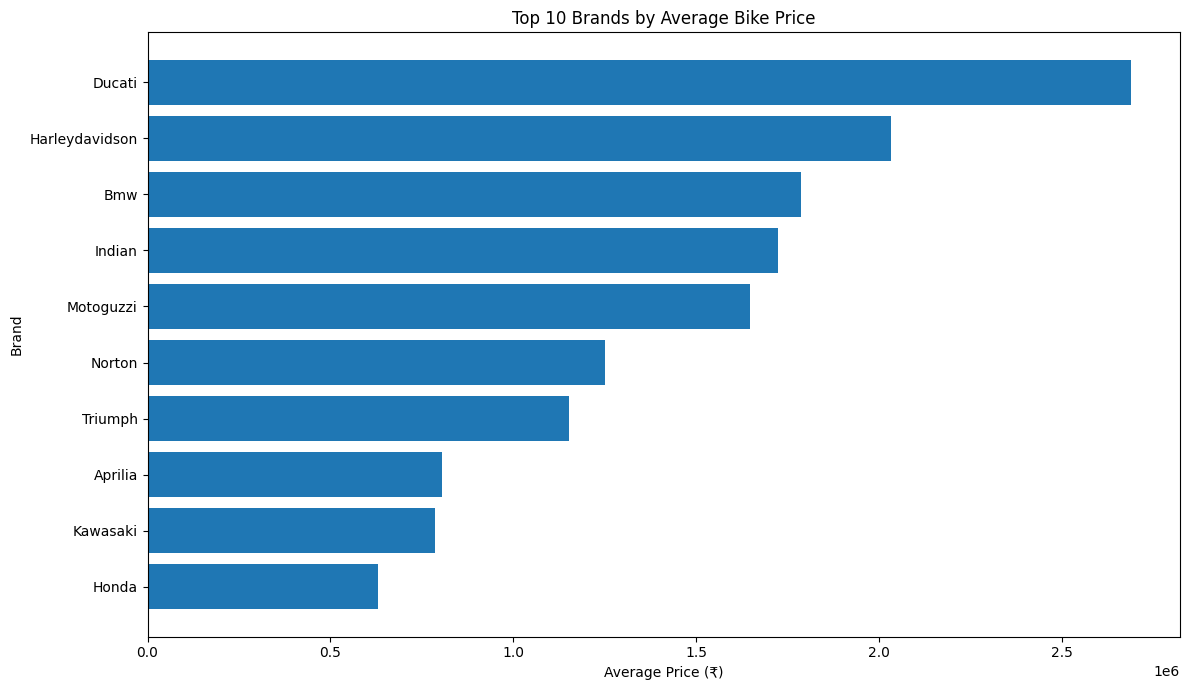

In [50]:

# Average Price by Brand

brand_avg_price = (
    df_cleaned.groupby("Brand")["Price"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

brand_avg_price["Price"] = brand_avg_price["Price"].round(2)

print("Top 10 Brands by Average Bike Price:")
display(brand_avg_price.head(10))

print("\n10 Most Affordable Brands:")
display(
    brand_avg_price.tail(10)
    .sort_values("Price")
    .reset_index(drop=True)
)

# Horizontal Bar Chart
import matplotlib.pyplot as plt

top10 = brand_avg_price.head(10).sort_values("Price")

plt.figure(figsize=(12, 7))
plt.barh(top10["Brand"], top10["Price"])

plt.title("Top 10 Brands by Average Bike Price")
plt.xlabel("Average Price (₹)")
plt.ylabel("Brand")

plt.tight_layout()
plt.show()


Top 10 Brands by Average Mileage:


,Brand,Mileage_kmpl
0,Hero,52.02
1,Tvs,47.61
2,Yamaha,47.53
3,Bajaj,46.61
4,Honda,44.78
5,Vlf,42.0
6,Suzuki,41.0
7,Vespa,40.17
8,Keeway,39.17
9,Aprilia,33.92


10 Brands with Lowest Average Mileage:


,Brand,Mileage_kmpl
0,Ducati,17.1
1,Motomorini,20.0
2,Indian,21.0
3,Benelli,22.0
4,Bmw,22.88
5,Triumph,23.79
6,Bsa,25.0
7,Harleydavidson,27.0
8,Kawasaki,27.67
9,Royalenfield,29.2


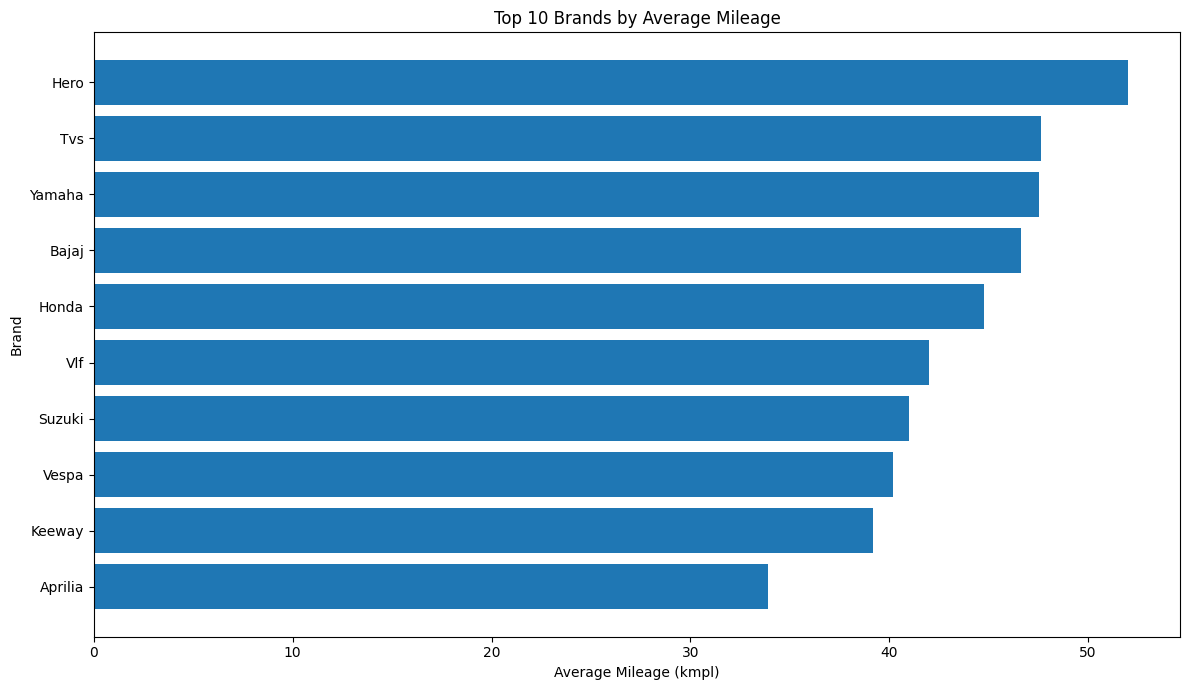

In [51]:

#Brand-wise Average Mileage

import matplotlib.pyplot as plt

# Calculate average mileage brand-wise
brand_avg_mileage = (
    df_cleaned.dropna(subset=["Mileage_kmpl"])
    .groupby("Brand")["Mileage_kmpl"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

brand_avg_mileage["Mileage_kmpl"] = (
    brand_avg_mileage["Mileage_kmpl"].round(2)
)

# Display top 10 brands
print("Top 10 Brands by Average Mileage:")
display(brand_avg_mileage.head(10))

# Display 10 brands with lowest average mileage
print("10 Brands with Lowest Average Mileage:")
display(
    brand_avg_mileage.tail(10)
    .sort_values("Mileage_kmpl")
    .reset_index(drop=True)
)

# Horizontal bar chart
top10 = brand_avg_mileage.head(10).sort_values("Mileage_kmpl")

plt.figure(figsize=(12, 7))
plt.barh(top10["Brand"], top10["Mileage_kmpl"])

plt.title("Top 10 Brands by Average Mileage")
plt.xlabel("Average Mileage (kmpl)")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()


Top 10 Highest Rated Bikes:


,Bike_Name,Brand,User_Rating,Price
0,Indian Super Scout,Indian,5.0,1725954.0
1,Okinawa Ridge 100,Okinawa,5.0,115311.0
2,Indian Chief Bobber Dark Horse,Indian,5.0,2286943.0
3,Harley-Davidson Street Glide,Harleydavidson,5.0,4250000.0
4,Indian Sport Scout,Indian,5.0,1505802.0
5,Moto Guzzi V85 TT,Motoguzzi,5.0,1645802.0
6,Indian Scout Sixty Bobber,Indian,5.0,1388244.0
7,Indian 101 Scout,Indian,5.0,1708855.0
8,Aprilia RSV4 1100 Factory,Aprilia,5.0,3340763.0
9,Aprilia Tuono 660,Aprilia,5.0,1863817.0


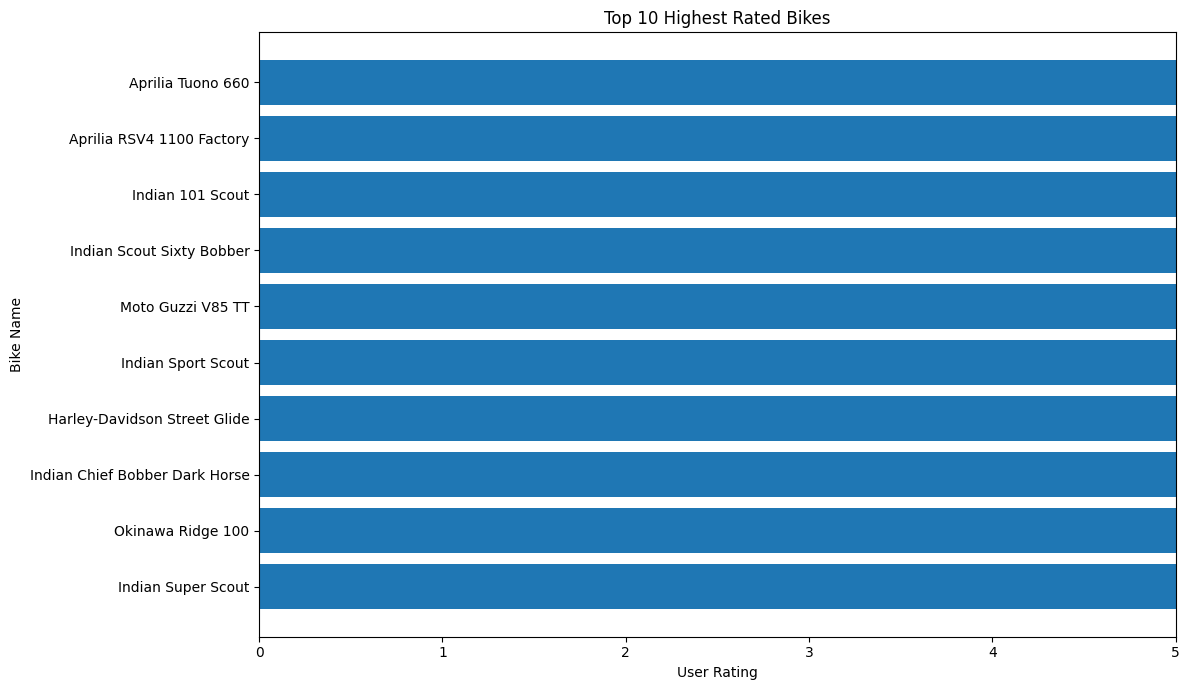

In [52]:

#Highest Rated Bikes

import matplotlib.pyplot as plt

# Select bikes with available ratings
highest_rated = (
    df_cleaned.dropna(subset=["User_Rating"])
    .sort_values("User_Rating", ascending=False)
    .drop_duplicates(subset=["Bike_Name"])
    .head(10)
)

# Display Top 10 highest rated bikes
print("Top 10 Highest Rated Bikes:")

display(
    highest_rated[
        ["Bike_Name", "Brand", "User_Rating", "Price"]
    ].reset_index(drop=True)
)

# Horizontal bar chart
top10 = highest_rated.sort_values("User_Rating")

plt.figure(figsize=(12, 7))
plt.barh(top10["Bike_Name"], top10["User_Rating"])

plt.title("Top 10 Highest Rated Bikes")
plt.xlabel("User Rating")
plt.ylabel("Bike Name")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()


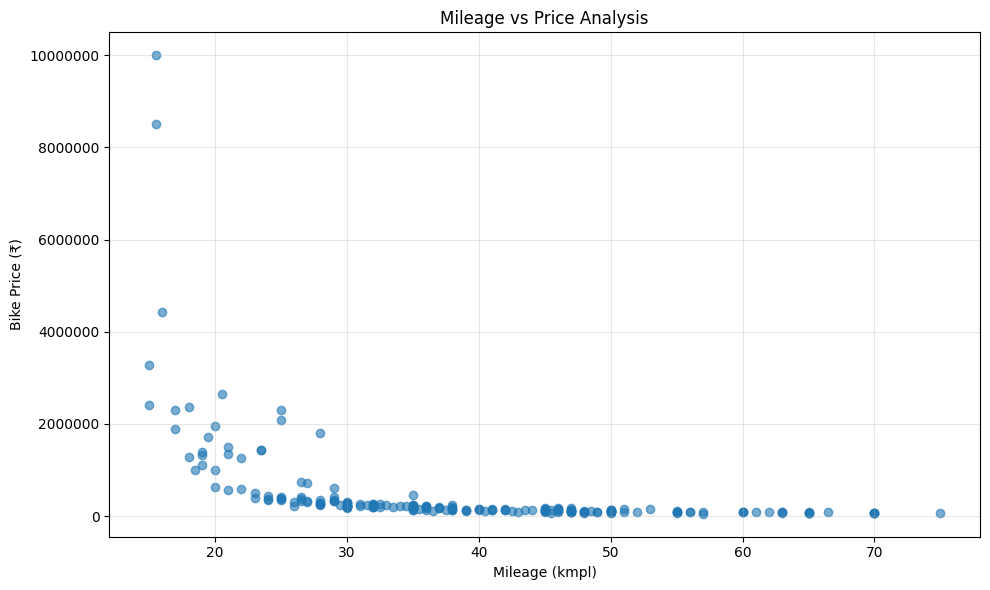

Correlation between Mileage and Price: -0.464


In [53]:
#Mileage vs Price Analysis

import matplotlib.pyplot as plt

# Select required columns and remove missing values
mileage_price = df_cleaned.dropna(
    subset=["Mileage_kmpl", "Price"]
)

# Scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    mileage_price["Mileage_kmpl"],
    mileage_price["Price"],
    alpha=0.6
)

plt.title("Mileage vs Price Analysis")
plt.xlabel("Mileage (kmpl)")
plt.ylabel("Bike Price (₹)")
plt.ticklabel_format(style="plain", axis="y")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Calculate correlation
correlation = mileage_price[
    ["Mileage_kmpl", "Price"]
].corr().iloc[0, 1]

print("Correlation between Mileage and Price:", round(correlation, 3))


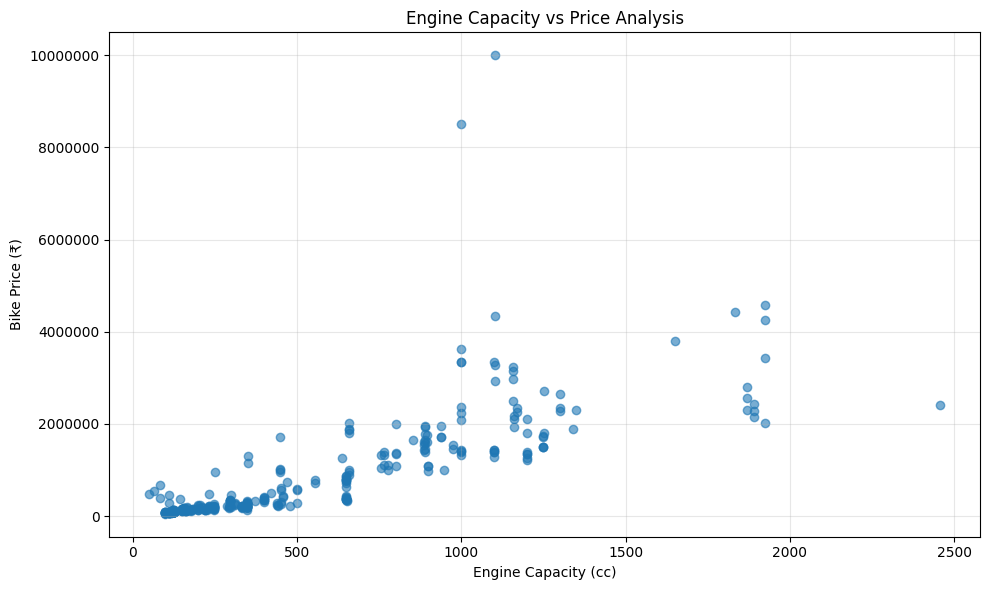

Correlation between Engine Capacity and Price: 0.765


In [54]:
#Engine Capacity vs Price Analysis

import matplotlib.pyplot as plt

engine_price = df_cleaned.dropna(
    subset=["Engine_Capacity_cc", "Price"]
)

plt.figure(figsize=(10, 6))

plt.scatter(
    engine_price["Engine_Capacity_cc"],
    engine_price["Price"],
    alpha=0.6
)

plt.title("Engine Capacity vs Price Analysis")
plt.xlabel("Engine Capacity (cc)")
plt.ylabel("Bike Price (₹)")
plt.ticklabel_format(style="plain", axis="y")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Calculate correlation
correlation = engine_price[
    ["Engine_Capacity_cc", "Price"]
].corr().iloc[0, 1]

print("Correlation between Engine Capacity and Price:",
      round(correlation, 3))


Top 10 Most Affordable Brands:


,Brand,Price
0,Yo,69400.00
1,Evolet,69499.00
2,Joyebike,76425.00
3,Lectrix,81683.00
4,Ivoomi,82499.00
5,Gemopai,87348.00
6,Ampere,98999.00
7,Vinfast,100000.00
8,Okinawa,101811.12
9,Odysse,108420.50


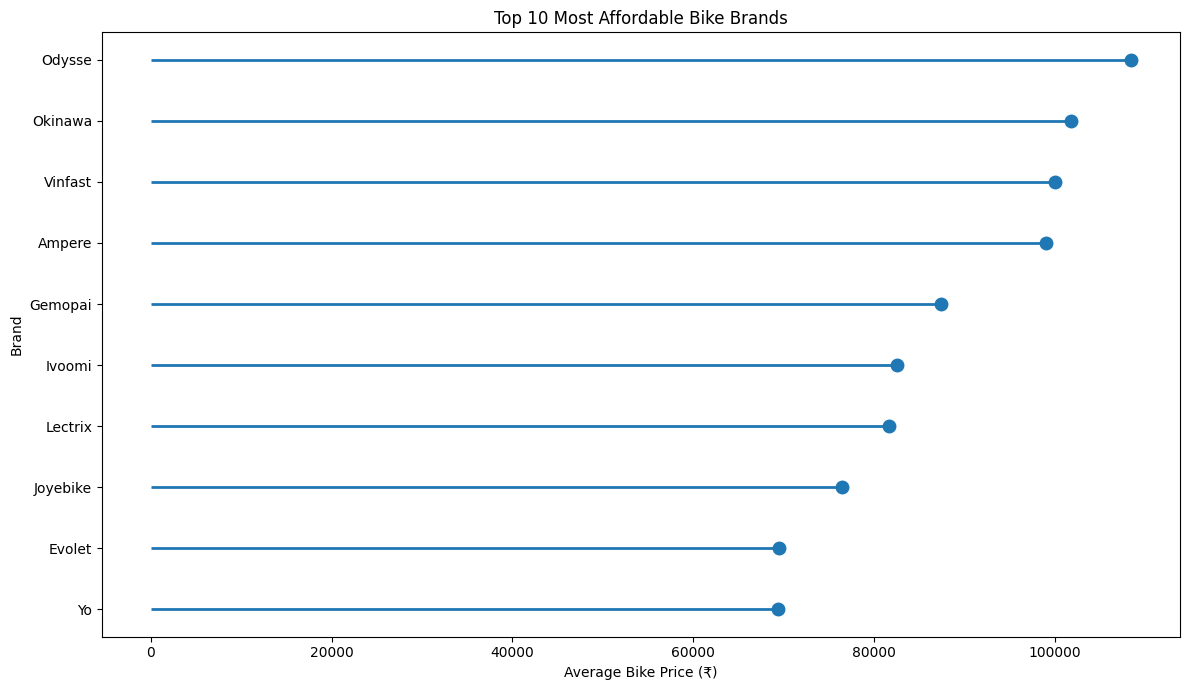

In [55]:
#Most Affordable Brands

import matplotlib.pyplot as plt

affordable_brands = (
    df_cleaned.groupby("Brand")["Price"]
    .mean()
    .sort_values(ascending=True)
    .reset_index()
)

affordable_brands["Price"] = affordable_brands["Price"].round(2)

# Display 10 most affordable brands
top10_affordable = affordable_brands.head(10)

print("Top 10 Most Affordable Brands:")
display(top10_affordable)

# Lollipop Chart
plt.figure(figsize=(12, 7))

plt.hlines(
    y=top10_affordable["Brand"],
    xmin=0,
    xmax=top10_affordable["Price"],
    linewidth=2
)

plt.plot(
    top10_affordable["Price"],
    top10_affordable["Brand"],
    "o",
    markersize=9
)

plt.title("Top 10 Most Affordable Bike Brands")
plt.xlabel("Average Bike Price (₹)")
plt.ylabel("Brand")

plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()


Top 10 Premium Bike Brands:


,Brand,Price
0,Ducati,2687909.32
1,Harleydavidson,2031909.40
2,Bmw,1786995.00
3,Indian,1724199.33
4,Motoguzzi,1645802.00
5,Norton,1250000.00
6,Triumph,1152996.66
7,Aprilia,805379.71
8,Kawasaki,786521.42
9,Honda,630996.78


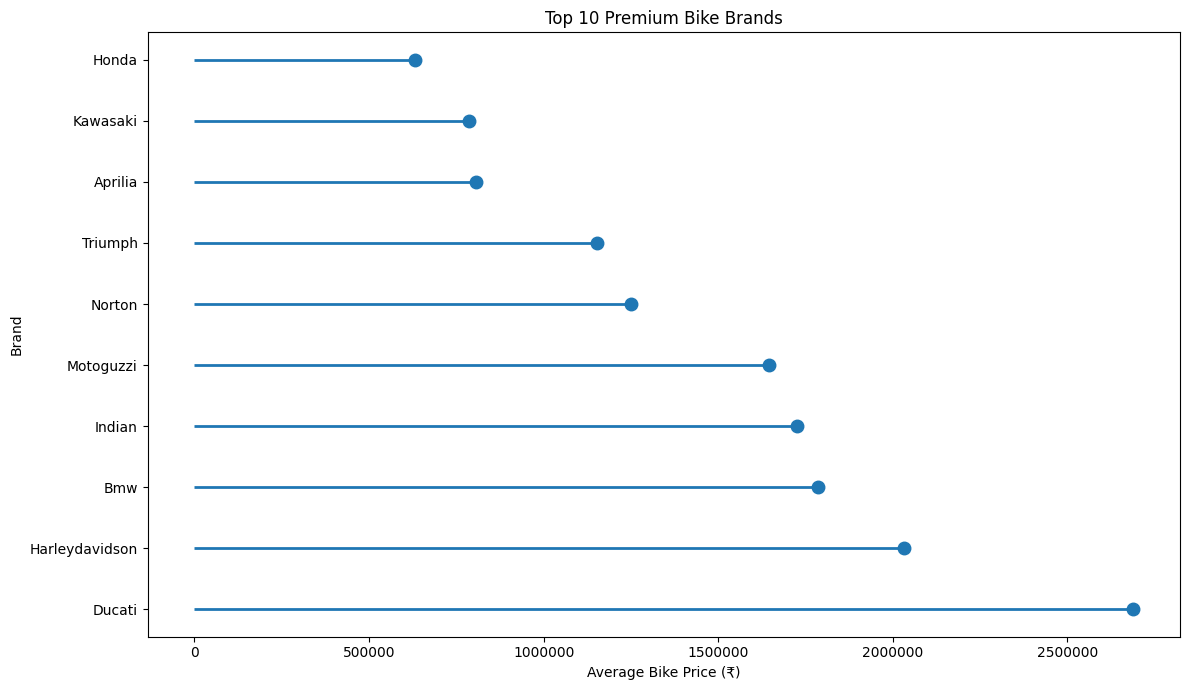

In [56]:
#Premium Bike Brands

import matplotlib.pyplot as plt

premium_brands = (
    df_cleaned.groupby("Brand")["Price"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

premium_brands["Price"] = premium_brands["Price"].round(2)

# Top 10 premium brands
top10_premium = premium_brands.head(10)

print("Top 10 Premium Bike Brands:")
display(top10_premium)

# Lollipop Chart
plt.figure(figsize=(12, 7))

plt.hlines(
    y=top10_premium["Brand"],
    xmin=0,
    xmax=top10_premium["Price"],
    linewidth=2
)

plt.plot(
    top10_premium["Price"],
    top10_premium["Brand"],
    "o",
    markersize=9
)

plt.title("Top 10 Premium Bike Brands")
plt.xlabel("Average Bike Price (₹)")
plt.ylabel("Brand")

plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()


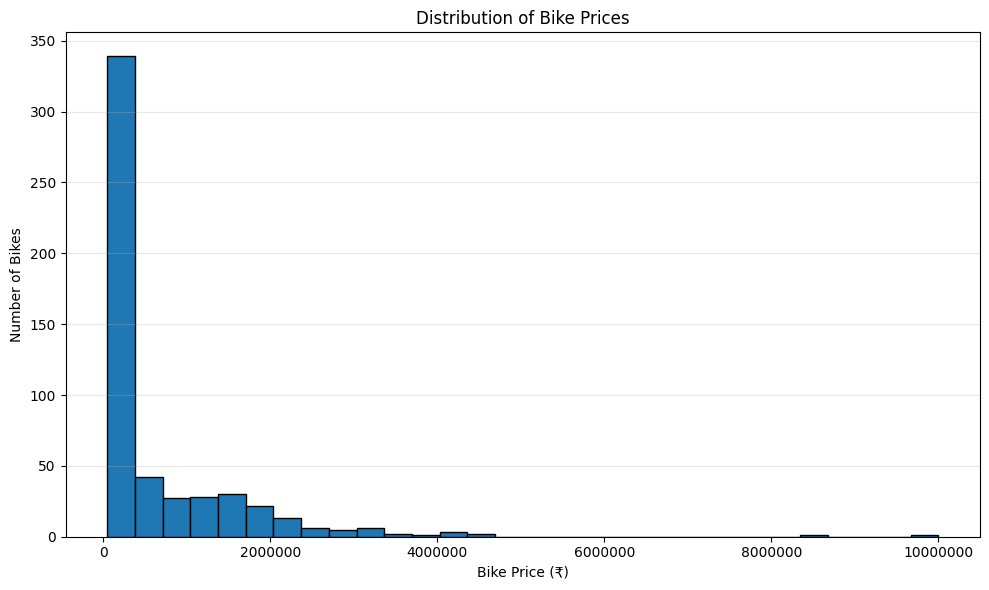

Price Distribution Statistics:


,Price
count,528.00
mean,660320.93
std,986119.09
min,47932.00
25%,120955.25
50%,220909.50
75%,910500.00
max,10000000.00


In [57]:
#Price Distribution

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(
    df_cleaned["Price"].dropna(),
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Bike Prices")
plt.xlabel("Bike Price (₹)")
plt.ylabel("Number of Bikes")

plt.ticklabel_format(style="plain", axis="x")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Price statistics
print("Price Distribution Statistics:")
display(df_cleaned["Price"].describe().round(2))


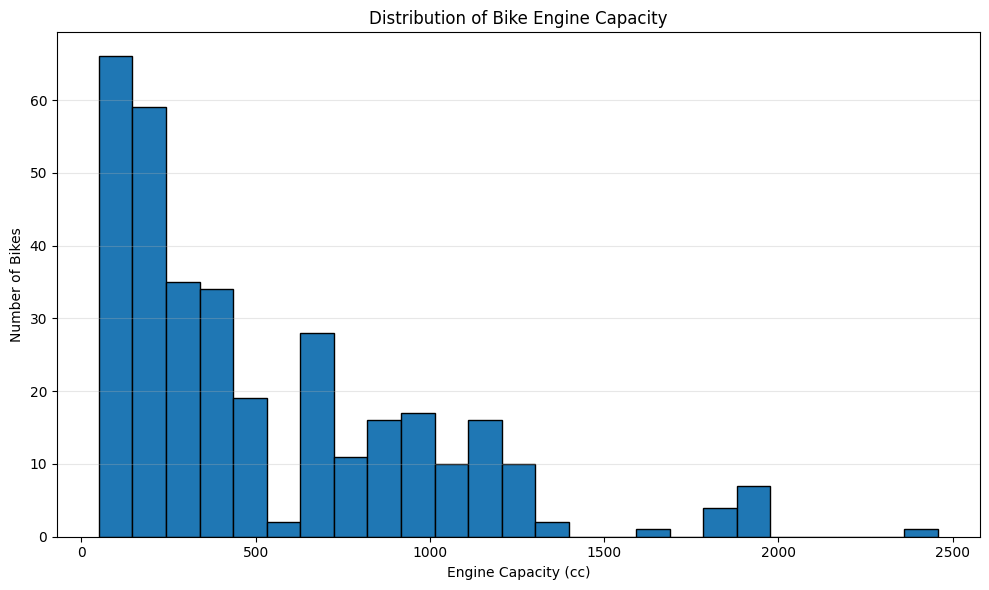

Engine Capacity Distribution Statistics:


,Engine_Capacity_cc
count,338.0
mean,527.08
std,457.85
min,49.9
25%,156.22
50%,349.0
75%,803.0
max,2458.0


In [58]:
#Engine Capacity Distribution

import matplotlib.pyplot as plt

engine_data = df_cleaned["Engine_Capacity_cc"].dropna()

plt.figure(figsize=(10, 6))

plt.hist(
    engine_data,
    bins=25,
    edgecolor="black"
)

plt.title("Distribution of Bike Engine Capacity")
plt.xlabel("Engine Capacity (cc)")
plt.ylabel("Number of Bikes")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Engine capacity statistics
print("Engine Capacity Distribution Statistics:")
display(engine_data.describe().round(2))


In [59]:
top_expensive = df_cleaned[
    ~df_cleaned["Bike_Name"].str.contains(
        "model available|onward",
        case=False,
        na=False
    )
].nlargest(10, "Price")

display(
    top_expensive[
        ["Bike_Name", "Brand", "Price", "Engine_Capacity_cc"]
    ]
)

,Bike_Name,Brand,Price,Engine_Capacity_cc
367,Ducati Panigale V4 Lamborghini,Ducati,10000000.0,1103.0
370,Ducati Panigale V4 R,Ducati,8499000.0,998.0
403,Harley-Davidson Road Glide,Harleydavidson,4575000.0,1923.0
106,Honda Goldwing,Honda,4430000.0,1833.0
383,Ducati Multistrada V4 RS,Ducati,4346700.0,1103.0
409,Harley-Davidson Street Glide,Harleydavidson,4250000.0,1923.0
351,BMW K 1600,Bmw,3800000.0,1649.0
257,Kawasaki Ninja H2 SX SE,Kawasaki,3628000.0,998.0
404,Harley-Davidson Breakout,Harleydavidson,3436000.0,1923.0
104,Honda CBR1000RR-R Fireblade,Honda,3350000.0,1000.0


TOP 10 MOST EXPENSIVE BIKES


,Bike_Name,Brand,Price,Engine_Capacity_cc
0,Ducati Panigale V4 Lamborghini,Ducati,10000000.0,1103.0
1,Ducati Panigale V4 R,Ducati,8499000.0,998.0
2,Harley-Davidson Road Glide,Harleydavidson,4575000.0,1923.0
3,Honda Goldwing,Honda,4430000.0,1833.0
4,Ducati Multistrada V4 RS,Ducati,4346700.0,1103.0
5,Harley-Davidson Street Glide,Harleydavidson,4250000.0,1923.0
6,BMW K 1600,Bmw,3800000.0,1649.0
7,Kawasaki Ninja H2 SX SE,Kawasaki,3628000.0,998.0
8,Harley-Davidson Breakout,Harleydavidson,3436000.0,1923.0
9,Honda CBR1000RR-R Fireblade,Honda,3350000.0,1000.0


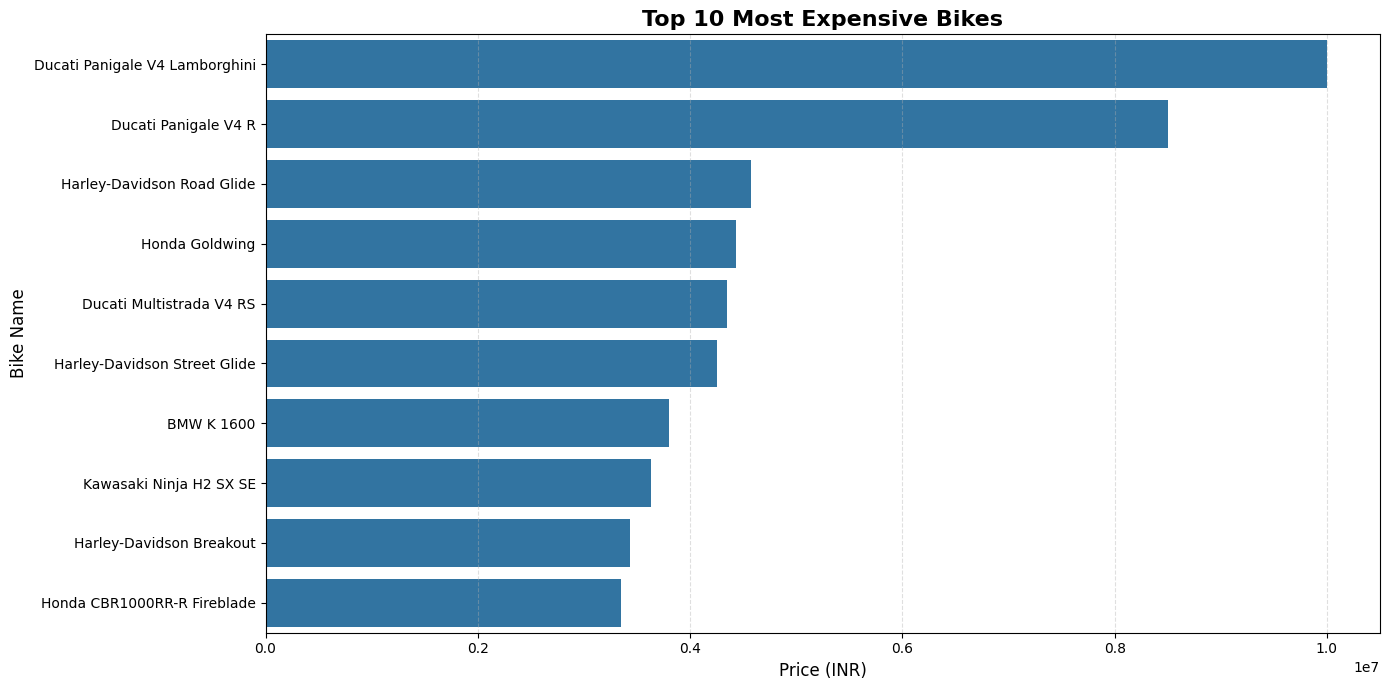

In [60]:
#TOP 10 MOST EXPENSIVE BIKES

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Create a copy of cleaned dataset
df_expensive = df_cleaned.copy()

# Step 2: Remove invalid or unwanted bike names
df_expensive = df_expensive[
    df_expensive["Bike_Name"].notna()
]

df_expensive = df_expensive[
    ~df_expensive["Bike_Name"].str.contains(
        r"model available|onward|view price|emi",
        case=False,
        na=False
    )
]

# Step 3: Ensure Price is numeric
df_expensive["Price"] = pd.to_numeric(
    df_expensive["Price"],
    errors="coerce"
)

# Step 4: Sort bikes by price
df_expensive = df_expensive.dropna(subset=["Price"])

top_expensive = (
    df_expensive
    .sort_values(by="Price", ascending=False)
    .drop_duplicates(subset=["Bike_Name"])
    .head(10)
    .copy()
)

# Step 5: Display Top 10 table
print("TOP 10 MOST EXPENSIVE BIKES")
print("=" * 60)

display(
    top_expensive[
        ["Bike_Name", "Brand", "Price", "Engine_Capacity_cc"]
    ].reset_index(drop=True)
)

# Step 6: Create Bar Graph
plt.figure(figsize=(14, 7))

sns.barplot(
    data=top_expensive,
    x="Price",
    y="Bike_Name"
)

plt.title(
    "Top 10 Most Expensive Bikes",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Price (INR)", fontsize=12)
plt.ylabel("Bike Name", fontsize=12)

plt.xticks(rotation=0)
plt.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


Top 10 Brands by Number of Bikes:


,Brand,count
0,Honda,41
1,Kawasaki,40
2,Triumph,35
3,Ktm,33
4,Hero,31
5,Tvs,29
6,Bajaj,29
7,Yamaha,26
8,Ducati,25
9,Royalenfield,24


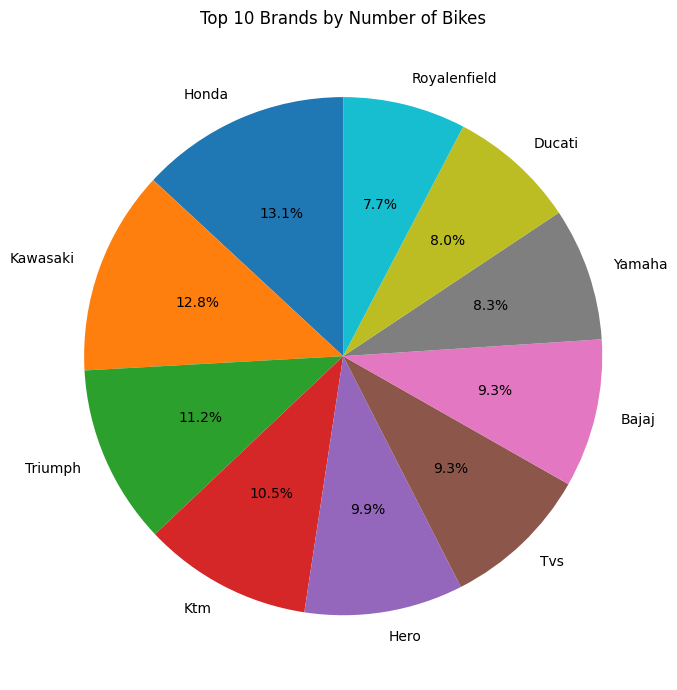

In [61]:
# Top 10 Brands by Number of Bikes - Pie Chart

import matplotlib.pyplot as plt

brand_counts = df_cleaned["Brand"].value_counts().head(10)

print("Top 10 Brands by Number of Bikes:")
display(brand_counts.reset_index())

plt.figure(figsize=(9, 7))

plt.pie(
    brand_counts,
    labels=brand_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Top 10 Brands by Number of Bikes")
plt.tight_layout()
plt.show()

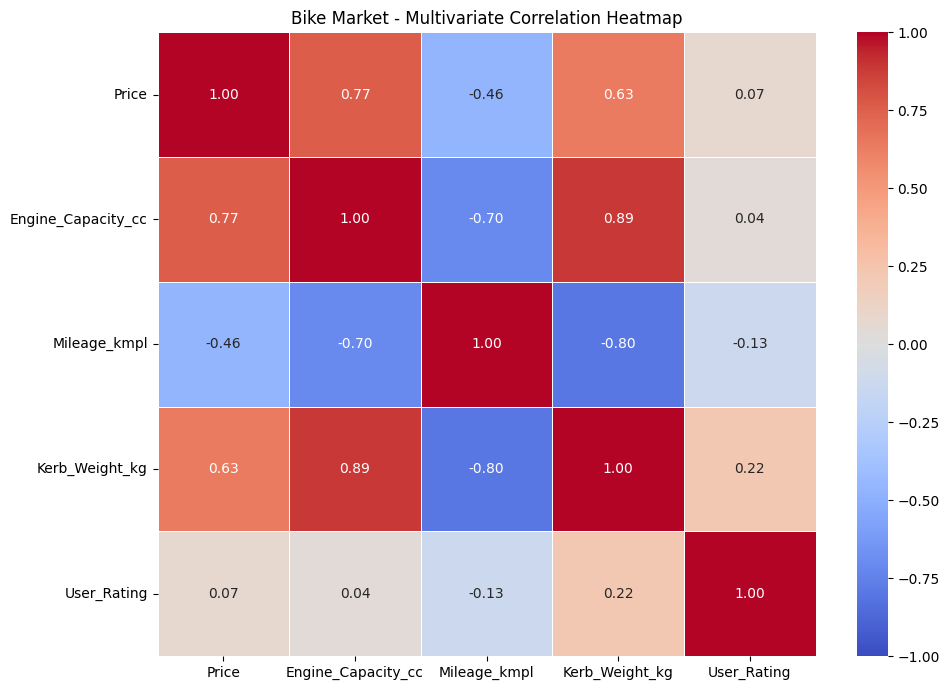

Correlation Matrix:


,Price,Engine_Capacity_cc,Mileage_kmpl,Kerb_Weight_kg,User_Rating
Price,1.00,0.77,-0.46,0.63,0.07
Engine_Capacity_cc,0.77,1.00,-0.70,0.89,0.04
Mileage_kmpl,-0.46,-0.70,1.00,-0.80,-0.13
Kerb_Weight_kg,0.63,0.89,-0.80,1.00,0.22
User_Rating,0.07,0.04,-0.13,0.22,1.00


In [62]:
#Multivariate Analysis - Correlation Heatmap

import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns
multi_data = df_cleaned[
    [
        "Price",
        "Engine_Capacity_cc",
        "Mileage_kmpl",
        "Kerb_Weight_kg",
        "User_Rating"
    ]
].corr()

# Create correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    multi_data,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Bike Market - Multivariate Correlation Heatmap")
plt.tight_layout()
plt.show()

# Display correlation values
print("Correlation Matrix:")
display(multi_data.round(2))


In [63]:
#Business Questions

print("BIKE MARKET ANALYSIS - BUSINESS QUESTIONS")
print("=" * 55)

# Q1. Which brand has the highest average bike price?
brand_avg_price = df_cleaned.groupby("Brand")["Price"].mean()
print("\nQ1. Which brand has the highest average bike price?")
print("Answer:", brand_avg_price.idxmax(),
      "- ₹", round(brand_avg_price.max(), 2))

# Q2. Which brand has the lowest average bike price?
print("\nQ2. Which brand has the lowest average bike price?")
print("Answer:", brand_avg_price.idxmin(),
      "- ₹", round(brand_avg_price.min(), 2))

# Q3. Which is the most expensive bike?
highest_bike = df_cleaned.loc[df_cleaned["Price"].idxmax()]
print("\nQ3. Which is the most expensive bike?")
print("Answer:", highest_bike["Bike_Name"],
      "(", highest_bike["Brand"], ")",
      "- ₹", highest_bike["Price"])

# Q4. Which is the most affordable bike?
lowest_bike = df_cleaned.loc[df_cleaned["Price"].idxmin()]
print("\nQ4. Which is the most affordable bike?")
print("Answer:", lowest_bike["Bike_Name"],
      "(", lowest_bike["Brand"], ")",
      "- ₹", lowest_bike["Price"])

# Q5. How many bikes and brands are available?
print("\nQ5. How many bikes and brands are available?")
print("Answer: Total Bikes =", len(df_cleaned))
print("Total Brands =", df_cleaned["Brand"].nunique())

# Q6. What is the average bike price?
print("\nQ6. What is the average bike price?")
print("Answer: ₹", round(df_cleaned["Price"].mean(), 2))

# Q7. What is the median bike price?
print("\nQ7. What is the median bike price?")
print("Answer: ₹", round(df_cleaned["Price"].median(), 2))

# Q8. What is the average engine capacity?
print("\nQ8. What is the average engine capacity?")
print("Answer:", round(df_cleaned["Engine_Capacity_cc"].mean(), 2), "cc")

# Q9. What is the relationship between engine capacity and price?
print("\nQ9. What is the relationship between engine capacity and price?")
corr_engine = df_cleaned["Price"].corr(
    df_cleaned["Engine_Capacity_cc"]
)
print("Answer: Correlation =", round(corr_engine, 2))

# Q10. What is the relationship between mileage and price?
print("\nQ10. What is the relationship between mileage and price?")
corr_mileage = df_cleaned["Price"].corr(
    df_cleaned["Mileage_kmpl"]
)
print("Answer: Correlation =", round(corr_mileage, 2))

print("\n" + "=" * 55)
print("ALL 10 BUSINESS QUESTIONS ANSWERED SUCCESSFULLY!")

BIKE MARKET ANALYSIS - BUSINESS QUESTIONS

Q1. Which brand has the highest average bike price?
Answer: Ducati - ₹ 2687909.32

Q2. Which brand has the lowest average bike price?
Answer: Yo - ₹ 69400.0

Q3. Which is the most expensive bike?
Answer: Ducati Panigale V4 Lamborghini ( Ducati ) - ₹ 10000000.0

Q4. Which is the most affordable bike?
Answer: TVS XL 100 Heavy Duty ( Tvs ) - ₹ 47932.0

Q5. How many bikes and brands are available?
Answer: Total Bikes = 528
Total Brands = 56

Q6. What is the average bike price?
Answer: ₹ 660320.93

Q7. What is the median bike price?
Answer: ₹ 220909.5

Q8. What is the average engine capacity?
Answer: 527.08 cc

Q9. What is the relationship between engine capacity and price?
Answer: Correlation = 0.77

Q10. What is the relationship between mileage and price?
Answer: Correlation = -0.46

ALL 10 BUSINESS QUESTIONS ANSWERED SUCCESSFULLY!


In [64]:
#Business Insights

print("BIKE MARKET ANALYSIS - KEY BUSINESS INSIGHTS")
print("=" * 55)

# Insight 1: Highest Average Price Brand
brand_avg_price = df_cleaned.groupby("Brand")["Price"].mean()

print("\n1. Highest Average Price Brand:")
print(brand_avg_price.idxmax(), "- ₹", round(brand_avg_price.max(), 2))

# Insight 2: Lowest Average Price Brand
print("\n2. Lowest Average Price Brand:")
print(brand_avg_price.idxmin(), "- ₹", round(brand_avg_price.min(), 2))

# Insight 3: Premium Bike Brands
print("\n3. Top 5 Premium Bike Brands:")
print(brand_avg_price.sort_values(ascending=False).head(5))

# Insight 4: Engine Capacity vs Price
print("\n4. Engine Capacity vs Price:")
print("Correlation:", round(
    df_cleaned["Engine_Capacity_cc"].corr(df_cleaned["Price"]), 2
))

# Insight 5: Mileage vs Price
print("\n5. Mileage vs Price:")
print("Correlation:", round(
    df_cleaned["Mileage_kmpl"].corr(df_cleaned["Price"]), 2
))

# Insight 6: Average Price vs Median Price
print("\n6. Average Price and Median Price:")
print("Average Price: ₹", round(df_cleaned["Price"].mean(), 2))
print("Median Price: ₹", round(df_cleaned["Price"].median(), 2))

# Insight 7: Engine Capacity vs Kerb Weight
print("\n7. Engine Capacity vs Kerb Weight:")
print("Correlation:", round(
    df_cleaned["Engine_Capacity_cc"].corr(df_cleaned["Kerb_Weight_kg"]), 2
))

# Insight 8: Data Availability
print("\n8. Data Availability:")
print("Total Bikes:", len(df_cleaned))
print("Mileage Data Available:",
      df_cleaned["Mileage_kmpl"].notna().sum())
print("Engine Capacity Data Available:",
      df_cleaned["Engine_Capacity_cc"].notna().sum())

print("\n" + "=" * 55)
print("ALL 8 BUSINESS INSIGHTS GENERATED SUCCESSFULLY!")

BIKE MARKET ANALYSIS - KEY BUSINESS INSIGHTS

1. Highest Average Price Brand:
Ducati - ₹ 2687909.32

2. Lowest Average Price Brand:
Yo - ₹ 69400.0

3. Top 5 Premium Bike Brands:
Brand
Ducati            2.687909e+06
Harleydavidson    2.031909e+06
Bmw               1.786995e+06
Indian            1.724199e+06
Motoguzzi         1.645802e+06
Name: Price, dtype: float64

4. Engine Capacity vs Price:
Correlation: 0.77

5. Mileage vs Price:
Correlation: -0.46

6. Average Price and Median Price:
Average Price: ₹ 660320.93
Median Price: ₹ 220909.5

7. Engine Capacity vs Kerb Weight:
Correlation: 0.89

8. Data Availability:
Total Bikes: 528
Mileage Data Available: 208
Engine Capacity Data Available: 338

ALL 8 BUSINESS INSIGHTS GENERATED SUCCESSFULLY!


In [65]:
#Business Recommendations

print("BIKE MARKET ANALYSIS - BUSINESS RECOMMENDATIONS")
print("=" * 60)

recommendations = [

    "1. Focus on Affordable Bikes:\n"
    "   Manufacturers should offer budget-friendly bikes to attract "
    "price-conscious customers.",

    "2. Improve Fuel Efficiency:\n"
    "   Companies should develop bikes with better mileage to attract "
    "customers looking for fuel savings.",

    "3. Develop Different Engine Categories:\n"
    "   Manufacturers should provide different engine capacities "
    "to meet the needs of different customer segments.",

    "4. Maintain Competitive Pricing:\n"
    "   Companies should set competitive prices based on bike features, "
    "engine capacity and brand positioning.",

    "5. Improve Product Information:\n"
    "   Bike companies should provide complete and accurate details "
    "about mileage, engine capacity, weight and other specifications."
]

for recommendation in recommendations:
    print("\n" + recommendation)

print("\n" + "=" * 60)
print("ALL 5 BUSINESS RECOMMENDATIONS GENERATED SUCCESSFULLY!")

BIKE MARKET ANALYSIS - BUSINESS RECOMMENDATIONS

1. Focus on Affordable Bikes:
   Manufacturers should offer budget-friendly bikes to attract price-conscious customers.

2. Improve Fuel Efficiency:
   Companies should develop bikes with better mileage to attract customers looking for fuel savings.

3. Develop Different Engine Categories:
   Manufacturers should provide different engine capacities to meet the needs of different customer segments.

4. Maintain Competitive Pricing:
   Companies should set competitive prices based on bike features, engine capacity and brand positioning.

5. Improve Product Information:
   Bike companies should provide complete and accurate details about mileage, engine capacity, weight and other specifications.

ALL 5 BUSINESS RECOMMENDATIONS GENERATED SUCCESSFULLY!


## Final submission export

Run the next cell after the analysis to save the raw and cleaned CSV files and export the Matplotlib figures.

In [69]:
# FINAL SUBMISSION EXPORT
# Run this cell after all scraping, cleaning, and visualization cells have completed.
from pathlib import Path
import matplotlib.pyplot as plt

submission_dir = Path("Bike_Market_Analysis_Submission")
plots_dir = submission_dir / "visualizations"
plots_dir.mkdir(parents=True, exist_ok=True)

# Save datasets (these are the actual DataFrames created by this notebook).
df_raw.to_csv(submission_dir / "bike_market_raw.csv", index=False)
df_cleaned.to_csv(submission_dir / "bike_market_cleaned.csv", index=False)

# Export all currently-created Matplotlib figures.
for figure_number in plt.get_fignums():
    fig = plt.figure(figure_number)
    fig.savefig(plots_dir / f"visualization_{figure_number:02d}.png", dpi=160, bbox_inches="tight")

print("Submission files saved to:", submission_dir.resolve())
print("Raw dataset:", len(df_raw), "rows")
print("Cleaned dataset:", len(df_cleaned), "rows")


Submission files saved to: /content/Bike_Market_Analysis_Submission
Raw dataset: 528 rows
Cleaned dataset: 528 rows
